# BRFSS 2021 Health Status Classification

This notebook develops and compares binary classifiers for predicting whether a respondent reports **fair or poor health**.

## Libraries

In [80]:
from pathlib import Path
from time import perf_counter
import gc
import json
from datetime import datetime

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

%pip install catboost
from catboost import CatBoostClassifier
from scipy.sparse import issparse
from scipy.stats import wilcoxon

%pip install shap
import shap

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.feature_selection import RFECV, SelectKBest, mutual_info_classif
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    average_precision_score,
    balanced_accuracy_score,
    confusion_matrix,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    RepeatedStratifiedKFold,
    StratifiedKFold,
)
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.svm import LinearSVC
from sklearn.tree import DecisionTreeClassifier
from sklearn.decomposition import TruncatedSVD

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 100)
pd.set_option("display.max_rows", 100)


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.

[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
RANDOM_STATE = 42
PROJECT_DIR = Path.cwd()
DATA_PATH = PROJECT_DIR / "LLCP2021.csv"
RESULTS_DIR = PROJECT_DIR / "results"
RESULTS_DIR.mkdir(exist_ok=True)

DATA_PATH

PosixPath('/Users/toma/Downloads/STUDY & MASTERS/+UJM/M2 2026:27/M2 1st semester/ML Techniques/Project Session 3 (3 - oct)/LLCP2021.csv')

## Load and audit the data

In [3]:
df = pd.read_csv(DATA_PATH)
print(df.shape)
display(df.head())
df.info()

(438693, 303)


,_STATE,FMONTH,IDATE,IMONTH,IDAY,IYEAR,DISPCODE,SEQNO,_PSU,CTELENM1,PVTRESD1,COLGHOUS,STATERE1,CELPHON1,LADULT1,COLGSEX,NUMADULT,LANDSEX,NUMMEN,NUMWOMEN,RESPSLCT,SAFETIME,CTELNUM1,CELLFON5,CADULT1,CELLSEX,PVTRESD3,CCLGHOUS,CSTATE1,LANDLINE,HHADULT,SEXVAR,GENHLTH,PHYSHLTH,MENTHLTH,POORHLTH,PRIMINSR,PERSDOC3,MEDCOST1,CHECKUP1,EXERANY2,BPHIGH6,BPMEDS,CHOLCHK3,TOLDHI3,CHOLMED3,CVDINFR4,CVDCRHD4,CVDSTRK3,ASTHMA3,...,_PRACE1,_MRACE1,_HISPANC,_RACE,_RACEG21,_RACEGR3,_RACEPRV,_SEX,_AGEG5YR,_AGE65YR,_AGE80,_AGE_G,HTIN4,HTM4,WTKG3,_BMI5,_BMI5CAT,_RFBMI5,_CHLDCNT,_EDUCAG,_INCOMG1,_SMOKER3,_RFSMOK3,_CURECI1,DRNKANY5,DROCDY3_,_RFBING5,_DRNKWK1,_RFDRHV7,_FLSHOT7,_PNEUMO3,_AIDTST4,FTJUDA2_,FRUTDA2_,GRENDA1_,FRNCHDA_,POTADA1_,VEGEDA2_,_MISFRT1,_MISVEG1,_FRTRES1,_VEGRES1,_FRUTSU1,_VEGESU1,_FRTLT1A,_VEGLT1A,_FRT16A,_VEG23A,_FRUITE1,_VEGETE1
0,1,1,1192021,1,19,2021,1100,2021000001,2021000001,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,5.0,20.0,10.0,88.0,3.0,1.0,2.0,2.0,2.0,3.0,NaN,2.0,1.0,1.0,2.0,2.0,2.0,1.0,...,1.0,1.0,2,1,1,1,1,2,11,2,70,6,59.0,150.0,3266.0,1454.0,1.0,1,1,2,3,3,1,1,2,0,1,0,1,1.0,1.0,2.0,0.0,100.0,57.0,43.0,14.0,100.0,0,0,1,1,100.0,214.0,1,1,1,1,0,0
1,1,1,1212021,1,21,2021,1100,2021000002,2021000002,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,3.0,88.0,88.0,NaN,1.0,2.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,1.0,2.0,1.0,2.0,2.0,...,2.0,2.0,2,2,2,2,2,2,10,2,67,6,66.0,168.0,NaN,NaN,NaN,9,1,4,9,4,1,1,2,0,1,0,1,2.0,2.0,2.0,0.0,100.0,14.0,0.0,14.0,100.0,0,0,1,1,100.0,128.0,1,1,1,1,0,0
2,1,1,1212021,1,21,2021,1100,2021000003,2021000003,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2.0,88.0,88.0,NaN,2.0,2.0,2.0,1.0,2.0,1.0,1.0,2.0,2.0,2.0,2.0,1.0,2.0,2.0,...,2.0,2.0,2,2,2,2,2,2,11,2,72,6,65.0,165.0,7711.0,2829.0,3.0,2,1,2,2,4,1,1,2,0,1,0,1,2.0,2.0,2.0,0.0,100.0,0.0,14.0,14.0,43.0,0,0,1,1,100.0,71.0,1,2,1,1,0,0
3,1,1,1172021,1,17,2021,1100,2021000004,2021000004,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,2.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2,2.0,88.0,10.0,88.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,1.0,2.0,2.0,2.0,2.0,2.0,...,1.0,1.0,2,1,1,1,1,2,9,1,62,5,64.0,163.0,8845.0,3347.0,4.0,2,1,2,5,4,1,1,1,14,2,300,1,NaN,NaN,2.0,71.0,43.0,10.0,57.0,27.0,71.0,0,0,1,1,114.0,165.0,1,1,1,1,0,0
4,1,1,1152021,1,15,2021,1100,2021000005,2021000005,1.0,1.0,NaN,1.0,2.0,1.0,NaN,2.0,NaN,1.0,1.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1,5.0,30.0,88.0,30.0,3.0,1.0,2.0,1.0,1.0,4.0,NaN,2.0,1.0,1.0,1.0,7.0,1.0,2.0,...,1.0,7.0,2,7,2,4,7,1,12,2,76,6,71.0,180.0,9344.0,2873.0,3.0,2,1,1,2,4,1,1,2,0,1,0,1,1.0,1.0,1.0,0.0,100.0,100.0,29.0,29.0,100.0,0,0,1,1,100.0,258.0,1,1,1,1,0,0


<class 'pandas.DataFrame'>
RangeIndex: 438693 entries, 0 to 438692
Columns: 303 entries, _STATE to _VEGETE1
dtypes: float64(245), int64(58)
memory usage: 1014.1 MB


In [4]:
duplicate_count = df.duplicated().sum()
print("Fully duplicated rows:", duplicate_count)

Fully duplicated rows: 0


In [5]:
person_id_columns = ["_STATE", "SEQNO"]

duplicate_person_ids = df.duplicated(
    subset=person_id_columns,
    keep=False,
)

print(
    "Rows with duplicated person ID:",
    duplicate_person_ids.sum(),
)

Rows with duplicated person ID: 0


We remove variables related to the mechanics of the telephone survey while retaining medical, behavioral, and demographic predictors. The variable definitions are provided in the CDC questionnaire https://www.cdc.gov/brfss/annual_data/2021/pdf/codebook21_llcp-v2-508.pdf

In [6]:
record_metadata = [
    "_STATE",    # State code used to organize survey records
    "FMONTH",    # File month
    "IDATE",     # Interview date
    "IMONTH",    # Interview month
    "IDAY",      # Interview day
    "IYEAR",     # Interview year
    "DISPCODE",  # Final interview disposition
    "SEQNO",     # Survey record sequence number
    "_PSU",      # Primary sampling unit
]

survey_routing = [
    # Landline survey routing
    "CTELENM1",
    "PVTRESD1",
    "COLGHOUS",
    "STATERE1",
    "CELPHON1",
    "LADULT1",
    "COLGSEX",
    "NUMADULT",
    "LANDSEX",
    "NUMMEN",
    "NUMWOMEN",
    "RESPSLCT",

    # Cell-phone survey routing
    "SAFETIME",
    "CTELNUM1",
    "CELLFON5",
    "CADULT1",
    "CELLSEX",
    "PVTRESD3",
    "CCLGHOUS",
    "CSTATE1",
    "LANDLINE",
    "HHADULT",
]

telephone_ownership = [
    "NUMHHOL3",  # More than one household telephone number
    "NUMPHON3",  # Number of residential telephone numbers
    "CPDEMO1B",  # Number of personal cell phones
]

questionnaire_metadata = [
    "QSTVER",    # Questionnaire version
    "QSTLANG",   # Questionnaire language
]

survey_design_and_weights = [
    "MSCODE",    # Metropolitan status code used in survey weighting
    "_STSTR",    # Sample-design stratum
    "_STRWT",    # Stratum weight
    "_RAWRAKE",  # Raw raking factor
    "_WT2RAKE",  # Design weight used in raking
    "_IMPRACE",  # Race value imputed for weighting
    "_CHISPNC",  # Child Hispanic category used for weighting
    "_CRACE1",   # Child race category used for weighting
    "_CPRACE1",  # Preferred child race category
    "CAGEG",     # Child age group used for weighting
    "_CLLCPWT",  # Child landline/cell-phone weight
    "_DUALUSE",  # Dual telephone-use category
    "_DUALCOR",  # Dual telephone-use correction
    "_LLCPWT2",  # Intermediate survey weight
    "_LLCPWT",   # Final survey weight
]

service_columns = (
    record_metadata
    + survey_routing
    + telephone_ownership
    + questionnaire_metadata
    + survey_design_and_weights
)

In [7]:
df = df.drop(columns=service_columns)
df = df.drop(columns="_RFHLTH") # target leakage

print("Remaining columns:", df.shape[1])

Remaining columns: 251


In [8]:
target_table = (
    df["GENHLTH"]
    .value_counts(dropna=False)
    .sort_index()
    .rename_axis("value")
    .reset_index(name="count")
)

target_table["percent"] = target_table["count"] / len(df) * 100

display(target_table)

,value,count,percent
0,1.0,77741,17.721049
1,2.0,149112,33.990057
2,3.0,137938,31.442945
3,4.0,54736,12.477063
4,5.0,18005,4.104237
5,7.0,788,0.179624
6,9.0,369,0.084113
7,NaN,4,0.000912


In [9]:
# Target cleaning and definition
# GENHLTH values 7 (Don't know), 9 (Refused), 
# and missing values do not define a health class and are removed

rows_before = len(df)

df = df[df["GENHLTH"].isin([1, 2, 3, 4, 5])].copy()
df["GENHLTH"] = df["GENHLTH"].astype("int8")

print("Removed rows:", rows_before - len(df))
print("Remaining rows:", len(df))

display(
    df["GENHLTH"]
    .value_counts()
    .sort_index()
    .rename_axis("value")
    .reset_index(name="count")
)

Removed rows: 1161
Remaining rows: 437532


,value,count
0,1,77741
1,2,149112
2,3,137938
3,4,54736
4,5,18005


In [10]:
# Create binary target variable: 0 — excellent, very good, good; 1 — fair, poor
df["GENHLTH_BINARY"] = df["GENHLTH"].isin([4, 5]).astype("int8")

display(
    df["GENHLTH_BINARY"]
    .value_counts()
    .sort_index()
    .rename_axis("class")
    .reset_index(name="count")
)

,class,count
0,0,364791
1,1,72741


In [11]:
constant_columns = [
    column
    for column in df.columns
    if df[column].nunique(dropna=True) <= 1
]

print("Constant columns:", constant_columns)

Constant columns: ['TOLDCFS', 'HAVECFS', 'WORKCFS']


In [12]:
df = df.drop(columns=constant_columns)
print("Remaining columns:", df.shape[1])

Remaining columns: 249


In [13]:
column_names = {
    'SEXVAR': 'sex',
    'GENHLTH': 'health',
    'PHYSHLTH': 'physical_days',
    'MENTHLTH': 'mental_days',
    'POORHLTH': 'limited_days',
    'PRIMINSR': 'insurance',
    'PERSDOC3': 'personal_doctor',
    'MEDCOST1': 'cost_barrier',
    'CHECKUP1': 'last_checkup',
    'EXERANY2': 'exercise',
    'BPHIGH6': 'hypertension',
    'BPMEDS': 'bp_medication',
    'CHOLCHK3': 'cholesterol_check',
    'TOLDHI3': 'high_cholesterol',
    'CHOLMED3': 'cholesterol_med',
    'CVDINFR4': 'heart_attack',
    'CVDCRHD4': 'heart_disease',
    'CVDSTRK3': 'stroke',
    'ASTHMA3': 'asthma',
    'ASTHNOW': 'current_asthma',
    'CHCSCNCR': 'skin_cancer',
    'CHCOCNCR': 'other_cancer',
    'CHCCOPD3': 'copd',
    'ADDEPEV3': 'depression',
    'CHCKDNY2': 'kidney_disease',
    'DIABETE4': 'diabetes',
    'DIABAGE3': 'diabetes_age',
    'HAVARTH5': 'arthritis',
    'ARTHEXER': 'arthritis_exercise',
    'ARTHEDU': 'arthritis_class',
    'LMTJOIN3': 'joint_limit',
    'ARTHDIS2': 'work_arthritis',
    'JOINPAI2': 'joint_pain',
    'MARITAL': 'marital_status',
    'EDUCA': 'education',
    'RENTHOM1': 'housing',
    'VETERAN3': 'veteran',
    'EMPLOY1': 'employment',
    'CHILDREN': 'children',
    'INCOME3': 'income',
    'PREGNANT': 'pregnant',
    'WEIGHT2': 'weight',
    'HEIGHT3': 'height',
    'DEAF': 'deaf',
    'BLIND': 'blind',
    'DECIDE': 'cognitive_difficulty',
    'DIFFWALK': 'walking_difficulty',
    'DIFFDRES': 'dressing_difficulty',
    'DIFFALON': 'errand_difficulty',
    'SMOKE100': 'smoked_100',
    'SMOKDAY2': 'smoking_frequency',
    'USENOW3': 'smokeless_tobacco',
    'ECIGNOW1': 'ecigarette',
    'ALCDAY5': 'alcohol_frequency',
    'AVEDRNK3': 'average_drinks',
    'DRNK3GE5': 'binge_times',
    'MAXDRNKS': 'maximum_drinks',
    'FLUSHOT7': 'flu_vaccine',
    'FLSHTMY3': 'flu_date',
    'IMFVPLA2': 'flu_location',
    'PNEUVAC4': 'pneumonia_vaccine',
    'HIVTST7': 'hiv_test',
    'HIVTSTD3': 'hiv_date',
    'FRUIT2': 'fruit_frequency',
    'FRUITJU2': 'juice_frequency',
    'FVGREEN1': 'greens_frequency',
    'FRENCHF1': 'fries_frequency',
    'POTATOE1': 'potato_frequency',
    'VEGETAB2': 'vegetable_frequency',
    'PDIABTST': 'diabetes_test',
    'PREDIAB1': 'prediabetes',
    'INSULIN1': 'insulin',
    'BLDSUGAR': 'glucose_checks',
    'FEETCHK3': 'foot_checks',
    'DOCTDIAB': 'diabetes_visits',
    'CHKHEMO3': 'a1c_checks',
    'FEETCHK': 'foot_exams',
    'EYEEXAM1': 'eye_exam',
    'DIABEYE': 'diabetic_eye',
    'DIABEDU': 'diabetes_class',
    'TOLDHEPC': 'hepatitis_c',
    'TRETHEPC': 'hepc_treatment',
    'PRIRHEPC': 'hepc_prior',
    'HAVEHEPC': 'hepc_current',
    'HAVEHEPB': 'hepatitis_b',
    'MEDSHEPB': 'hepb_med',
    'HPVADVC4': 'hpv_vaccine',
    'HPVADSHT': 'hpv_doses',
    'TETANUS1': 'tetanus_vaccine',
    'SHINGLE2': 'shingles_vaccine',
    'LCSFIRST': 'smoking_start',
    'LCSLAST': 'smoking_stop',
    'LCSNUMCG': 'daily_cigarettes',
    'LCSCTSCN': 'lung_ct',
    'HADMAM': 'mammogram',
    'HOWLONG': 'mammogram_time',
    'CERVSCRN': 'cervical_screening',
    'CRVCLCNC': 'cervical_time',
    'CRVCLPAP': 'pap_test',
    'CRVCLHPV': 'hpv_test',
    'HADHYST2': 'hysterectomy',
    'PSATEST1': 'psa_test',
    'PSATIME1': 'psa_time',
    'PCPSARS2': 'psa_reason',
    'PCSTALK': 'psa_discussion',
    'HADSIGM4': 'endoscopy',
    'COLNSIGM': 'endoscopy_type',
    'COLNTES1': 'colonoscopy_time',
    'SIGMTES1': 'sigmoidoscopy_time',
    'LASTSIG4': 'last_endoscopy',
    'COLNCNCR': 'colorectal_test',
    'VIRCOLO1': 'virtual_colonoscopy',
    'VCLNTES1': 'virtual_time',
    'SMALSTOL': 'stool_test',
    'STOLTEST': 'stool_time',
    'STOOLDN1': 'stool_dna',
    'BLDSTFIT': 'cologuard',
    'SDNATES1': 'dna_time',
    'CNCRDIFF': 'cancer_count',
    'CNCRAGE': 'cancer_age',
    'CNCRTYP1': 'cancer_type',
    'CSRVTRT3': 'cancer_treatment',
    'CSRVDOC1': 'cancer_doctor',
    'CSRVSUM': 'treatment_summary',
    'CSRVRTRN': 'followup_instructions',
    'CSRVINST': 'written_instructions',
    'CSRVINSR': 'treatment_coverage',
    'CSRVDEIN': 'cancer_denial',
    'CSRVCLIN': 'clinical_trial',
    'CSRVPAIN': 'cancer_pain',
    'CSRVCTL2': 'pain_control',
    'HOMBPCHK': 'bp_advice',
    'HOMRGCHK': 'home_bp',
    'WHEREBP': 'bp_location',
    'SHAREBP': 'bp_sharing',
    'WTCHSALT': 'salt_reduction',
    'DRADVISE': 'salt_advice',
    'CIMEMLOS': 'memory_loss',
    'CDHOUSE': 'chores_limit',
    'CDASSIST': 'activity_help',
    'CDHELP': 'help_available',
    'CDSOCIAL': 'social_interference',
    'CDDISCUS': 'memory_discussion',
    'CAREGIV1': 'caregiver',
    'CRGVREL4': 'care_relationship',
    'CRGVLNG1': 'care_duration',
    'CRGVHRS1': 'care_hours',
    'CRGVPRB3': 'care_condition',
    'CRGVALZD': 'care_alzheimer',
    'CRGVPER1': 'personal_care',
    'CRGVHOU1': 'household_care',
    'CRGVEXPT': 'future_care',
    'ACEDEPRS': 'childhood_depression',
    'ACEDRINK': 'childhood_alcohol',
    'ACEDRUGS': 'childhood_drugs',
    'ACEPRISN': 'childhood_prison',
    'ACEDIVRC': 'parental_divorce',
    'ACEPUNCH': 'parental_violence',
    'ACEHURT1': 'physical_abuse',
    'ACESWEAR': 'verbal_abuse',
    'ACETOUCH': 'sexual_touch',
    'ACETTHEM': 'forced_touch',
    'ACEHVSEX': 'forced_sex',
    'ACEADSAF': 'childhood_safety',
    'ACEADNED': 'childhood_needs',
    'MARIJAN1': 'marijuana_days',
    'USEMRJN3': 'marijuana_method',
    'RSNMRJN2': 'marijuana_reason',
    'LASTSMK2': 'quit_interval',
    'STOPSMK2': 'quit_attempt',
    'FIREARM5': 'firearms',
    'GUNLOAD': 'loaded_firearm',
    'LOADULK2': 'unlocked_firearm',
    'RCSGENDR': 'child_gender',
    'RCSRLTN2': 'child_relationship',
    'CASTHDX2': 'child_asthma',
    'CASTHNO2': 'child_asthma_now',
    'BIRTHSEX': 'birth_sex',
    'SOMALE': 'male_orientation',
    'SOFEMALE': 'female_orientation',
    'TRNSGNDR': 'transgender',
    '_METSTAT': '_metro',
    '_URBSTAT': '_urban',
    '_PHYS14D': '_physical_status',
    '_MENT14D': '_mental_status',
    '_HLTHPLN': '_insured',
    '_HCVU652': '_insured_under65',
    '_TOTINDA': '_physical_activity',
    '_RFHYPE6': '_hypertension',
    '_CHOLCH3': '_cholesterol_check',
    '_RFCHOL3': '_high_cholesterol',
    '_MICHD': '_heart_disease',
    '_LTASTH1': '_lifetime_asthma',
    '_CASTHM1': '_current_asthma',
    '_ASTHMS1': '_asthma_status',
    '_DRDXAR3': '_arthritis',
    '_LMTACT3': '_activity_limit',
    '_LMTWRK3': '_work_limit',
    '_PRACE1': '_preferred_race',
    '_MRACE1': '_multiracial',
    '_HISPANC': '_hispanic',
    '_RACE': '_race',
    '_RACEG21': '_race_binary',
    '_RACEGR3': '_race_group',
    '_RACEPRV': '_race_imputed',
    '_SEX': '_sex',
    '_AGEG5YR': '_age5_group',
    '_AGE65YR': '_age65_group',
    '_AGE80': '_age',
    '_AGE_G': '_age_group',
    'HTIN4': 'height_inches',
    'HTM4': 'height_meters',
    'WTKG3': 'weight_kg',
    '_BMI5': '_bmi',
    '_BMI5CAT': '_bmi_category',
    '_RFBMI5': '_overweight',
    '_CHLDCNT': '_child_count',
    '_EDUCAG': '_education_group',
    '_INCOMG1': '_income_group',
    '_SMOKER3': '_smoking_status',
    '_RFSMOK3': '_current_smoker',
    '_CURECI1': '_current_ecig',
    'DRNKANY5': 'alcohol_use',
    'DROCDY3_': 'drinks_daily',
    '_RFBING5': '_binge_drinking',
    '_DRNKWK1': '_drinks_weekly',
    '_RFDRHV7': '_heavy_drinking',
    '_FLSHOT7': '_flu_vaccine',
    '_PNEUMO3': '_pneumonia_vaccine',
    '_AIDTST4': '_hiv_test',
    'FTJUDA2_': 'juice_daily',
    'FRUTDA2_': 'fruit_daily',
    'GRENDA1_': 'greens_daily',
    'FRNCHDA_': 'fries_daily',
    'POTADA1_': 'potato_daily',
    'VEGEDA2_': 'vegetable_daily',
    '_MISFRT1': '_fruit_missing',
    '_MISVEG1': '_vegetable_missing',
    '_FRTRES1': '_fruit_response',
    '_VEGRES1': '_vegetable_response',
    '_FRUTSU1': '_fruit_total',
    '_VEGESU1': '_vegetable_total',
    '_FRTLT1A': '_fruit_once',
    '_VEGLT1A': '_vegetable_once',
    '_FRT16A': '_fruit_excess',
    '_VEG23A': '_vegetable_excess',
    '_FRUITE1': '_fruit_excluded',
    '_VEGETE1': '_vegetable_excluded',
    'GENHLTH_BINARY': 'health_binary',
}

df = df.rename(columns=column_names)

print("Renamed columns:", len(column_names))
print("Current shape:", df.shape)

Renamed columns: 249
Current shape: (437532, 249)


In [14]:
unique_counts = df.nunique(dropna=True).sort_values(ascending=False)

display(unique_counts.rename("unique_non_missing_count").to_frame())

,unique_non_missing_count
_bmi,3887
_vegetable_total,2358
_fruit_total,728
weight,586
weight_kg,571
...,...
_heart_disease,2
_urban,2
_metro,2
hepb_med,2


In [15]:
missing_by_column = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_%": df.isna().mean() * 100,
}).sort_values("missing_count", ascending=False)
with pd.option_context("display.max_rows", None):
    display(missing_by_column)

,missing_count,missing_%
sigmoidoscopy_time,437469,99.985601
hepb_med,437437,99.978287
hepc_prior,437371,99.963203
hepc_current,437371,99.963203
hepc_treatment,437371,99.963203
virtual_time,437331,99.954061
dna_time,437144,99.911321
cologuard,437144,99.911321
pain_control,436687,99.806871
last_endoscopy,436592,99.785159


Features with more than 50% missing values were removed. Most of these variables belong to optional survey modules or contain detailed follow-up questions asked only to specific subgroups, such as respondents with cancer, diabetes, asthma, or arthritis. The 50% threshold was selected because it represents a clear gap in the observed missingness distribution: the last removed feature had 51.73% missing values, while the next retained feature had 46.85%. General diagnostic variables, including indicators of diabetes, asthma, cancer, cardiovascular disease, COPD, kidney disease, and arthritis, were retained and have less than approximately 1% missing data. Thus, the filtering removes poorly covered conditional details while preserving the main medical, behavioral, and demographic information for the full study population.

In [16]:
missing_threshold = 50

high_missing_columns = missing_by_column.index[
    missing_by_column["missing_%"] > missing_threshold
].tolist()

print("Columns removed:", len(high_missing_columns))
print("Columns remaining:", df.shape[1] - len(high_missing_columns))

df = df.drop(columns=high_missing_columns)

Columns removed: 129
Columns remaining: 120


## NaN handling

In [18]:
target_columns = [
    "health",
    "health_binary",
]

numerical_candidates = [
    # Age
    "_age",

    # Body measurements
    "height_inches",
    "height_meters",
    "weight_kg",
    "_bmi",

    # Daily food-consumption frequencies
    "juice_daily",
    "fruit_daily",
    "greens_daily",
    "fries_daily",
    "potato_daily",
    "vegetable_daily",

    # Total daily consumption
    "_fruit_total",
    "_vegetable_total",
]

In [19]:
mixed_encoded_candidates = [
    # Number of unhealthy days:
    # 1-30 = days, 88 = none, 77/99 = unknown/refused
    "physical_days",
    "mental_days",
    "limited_days",

    # Age at diagnosis and pain scale
    "diabetes_age",
    "joint_pain",

    # Number of children:
    # 1-87 = number, 88 = none, 99 = refused
    "children",

    # Encoded weight and height with different measurement systems
    "weight",
    "height",

    # Alcohol frequency and quantity
    "alcohol_frequency",
    "average_drinks",
    "binge_times",
    "maximum_drinks",

    # Encoded dates
    "flu_date",
    "hiv_date",

    # Encoded food frequencies
    "fruit_frequency",
    "juice_frequency",
    "greens_frequency",
    "fries_frequency",
    "potato_frequency",
    "vegetable_frequency",

    # Encoded diabetes monitoring frequencies
    "glucose_checks",
    "foot_checks",

    # Numerical counts with special response codes
    "diabetes_visits",
    "a1c_checks",
    "foot_exams",

    # Lung-cancer screening quantities
    "smoking_start",
    "smoking_stop",
    "daily_cigarettes",

    # Age at cancer diagnosis
    "cancer_age",

    # Number of marijuana-use days
    "marijuana_days",

    # CDC-calculated alcohol quantities with missing-value codes
    "drinks_daily",
    "_drinks_weekly",
]

In [20]:
numerical_features = [
    column
    for column in numerical_candidates
    if column in df.columns
]

mixed_encoded_features = [
    column
    for column in mixed_encoded_candidates
    if column in df.columns
]

categorical_features = [
    column
    for column in df.columns
    if column not in target_columns
    and column not in numerical_features
    and column not in mixed_encoded_features
]

In [21]:
print("Numerical features:", len(numerical_features))
print("Mixed encoded features:", len(mixed_encoded_features))
print("Categorical features:", len(categorical_features))

print(
    "Total predictors:",
    len(numerical_features)
    + len(mixed_encoded_features)
    + len(categorical_features),
)

print("Expected predictors:", df.shape[1] - len(target_columns))

Numerical features: 13
Mixed encoded features: 15
Categorical features: 90
Total predictors: 118
Expected predictors: 118


In [22]:
feature_type_table = pd.DataFrame({
    "column": (
        numerical_features
        + mixed_encoded_features
        + categorical_features
    ),
    "feature_type": (
        ["numerical"] * len(numerical_features)
        + ["mixed_encoded"] * len(mixed_encoded_features)
        + ["categorical"] * len(categorical_features)
    ),
}).sort_values(
    ["feature_type", "column"]
).reset_index(drop=True)

with pd.option_context("display.max_rows", None):
    display(feature_type_table)

,column,feature_type
0,_activity_limit,categorical
1,_age5_group,categorical
2,_age65_group,categorical
3,_age_group,categorical
4,_arthritis,categorical
5,_asthma_status,categorical
6,_binge_drinking,categorical
7,_bmi_category,categorical
8,_child_count,categorical
9,_cholesterol_check,categorical


In [23]:
# Mixed encoded features are those that are stored as integers but have special codes 
# for missing values or other non-numeric responses. For example, a feature might 
# represent the number of days a person exercised in the past month, with values 
# from 0 to 30 representing actual days, and special codes like 77 for "unknown" 
# or 88 for "none". These features already have numeric analogs in the dataset, 
# so we can drop them to avoid redundancy and potential confusion in the model
raw_features_with_numeric_analogs = [
    "weight",
    "height",
    "alcohol_frequency",
    "fruit_frequency",
    "juice_frequency",
    "greens_frequency",
    "fries_frequency",
    "potato_frequency",
    "vegetable_frequency",
]

df = df.drop(columns=raw_features_with_numeric_analogs)

print("Remaining columns:", df.shape[1])

Remaining columns: 111


In [24]:
# Remaining mixed encoded features, considered as categorical
remaining_mixed_features = [
    "physical_days",
    "mental_days",
    "limited_days",
    "children",
    "drinks_daily",
    "_drinks_weekly",
]

In [25]:
numerical_features = [
    column
    for column in numerical_candidates
    if column in df.columns
]

categorical_features = [
    column
    for column in df.columns
    if column not in target_columns
    and column not in numerical_features
]

df_eda = df.copy()

# Includes ordinary categorical and mixed-encoded features
df_eda[categorical_features] = (
    df_eda[categorical_features]
    .fillna(-1)
)

# Numerical features
numerical_medians = df_eda[numerical_features].median()

df_eda[numerical_features] = (
    df_eda[numerical_features]
    .fillna(numerical_medians)
)

print("Remaining NaN values:", df_eda.isna().sum().sum())
print("EDA dataframe shape:", df_eda.shape)

Remaining NaN values: 0
EDA dataframe shape: (437532, 111)


## Exploratory data analysis

EDA is performed on the cleaned variables before one-hot encoding. The original `df` is used to describe blank values, while `df_eda` contains group-specific replacements for visual analysis: categorical blanks are represented by `-1`, and numerical blanks are replaced by the median.

In [26]:
original_target_distribution = (
    df_eda["health"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .rename("percent")
    .to_frame()
)
display(original_target_distribution)

,percent
health,
1,17.768072
2,34.080250
3,31.526380
4,12.510171
5,4.115128


In [27]:
binary_target_distribution = (
    df_eda["health_binary"]
    .value_counts(normalize=True)
    .sort_index()
    .mul(100)
    .rename("percent")
    .to_frame()
)
display(binary_target_distribution)

,percent
health_binary,
0,83.374702
1,16.625298


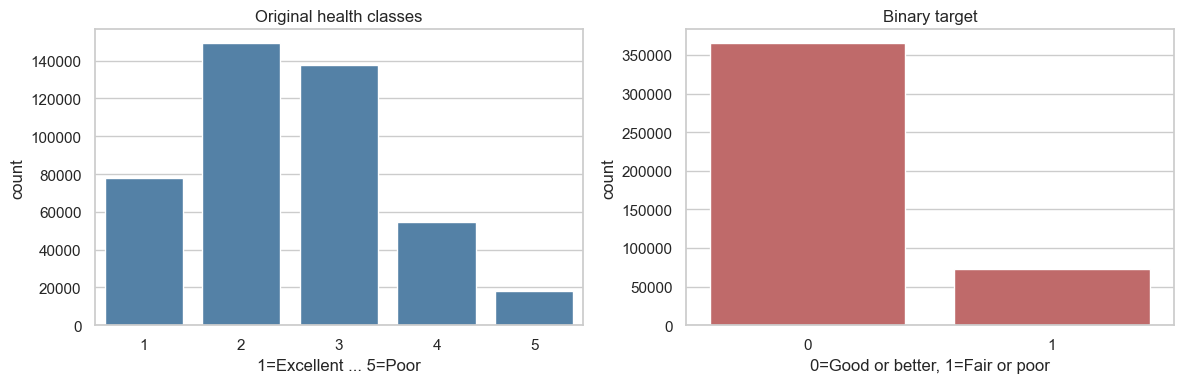

In [28]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(data=df_eda, x="health", ax=axes[0], color="steelblue")
axes[0].set_title("Original health classes")
axes[0].set_xlabel("1=Excellent ... 5=Poor")
sns.countplot(data=df_eda, x="health_binary", ax=axes[1], color="indianred")
axes[1].set_title("Binary target")
axes[1].set_xlabel("0=Good or better, 1=Fair or poor")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "target_distribution.png", dpi=160, bbox_inches="tight")
plt.show()

In [29]:
missing_plot = (
    df.isna().mean()
    .loc[lambda values: values > 0]
    .sort_values(ascending=False)
    .head(30)
)

display((missing_plot * 100).rename("missing_%").to_frame())

,missing_%
limited_days,46.846174
transgender,43.987640
cholesterol_med,13.995548
_high_cholesterol,13.900240
high_cholesterol,13.828246
_vegetable_total,13.633289
_fruit_total,11.591609
vegetable_daily,11.011766
potato_daily,10.993482
_bmi,10.644936


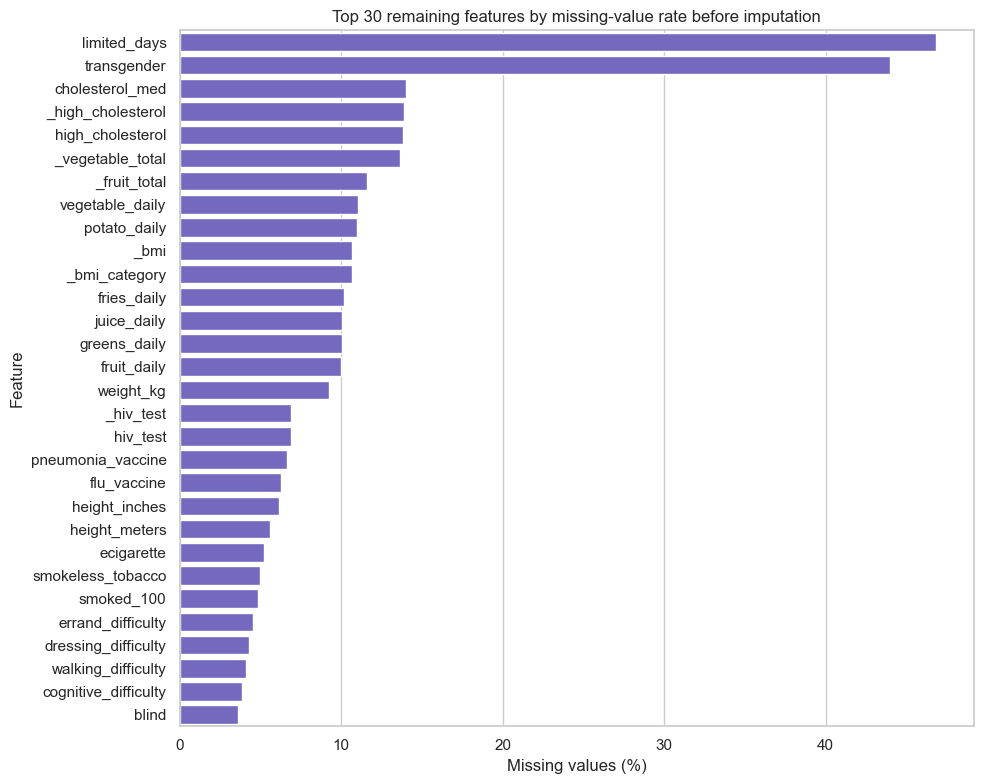

In [30]:
plt.figure(figsize=(10, 8))
sns.barplot(x=missing_plot.values * 100, y=missing_plot.index, color="slateblue")
plt.xlabel("Missing values (%)")
plt.ylabel("Feature")
plt.title("Top 30 remaining features by missing-value rate before imputation")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "missing_values_top30.png", dpi=160, bbox_inches="tight")
plt.show()

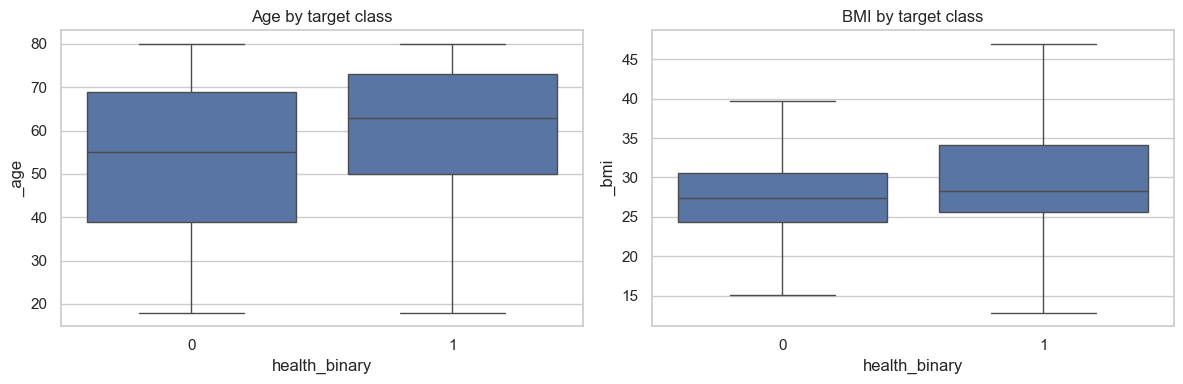

In [31]:
eda_numeric = df_eda[["health_binary"] + numerical_features].copy()

two_decimal_features = [
    "height_meters", "weight_kg", "_bmi",
    "juice_daily", "fruit_daily", "greens_daily",
    "fries_daily", "potato_daily", "vegetable_daily",
    "_fruit_total", "_vegetable_total",
]

for column in two_decimal_features:
    if column in eda_numeric.columns:
        eda_numeric[column] = eda_numeric[column] / 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.boxplot(data=eda_numeric, x="health_binary", y="_age", ax=axes[0], showfliers=False)
axes[0].set_title("Age by target class")
sns.boxplot(data=eda_numeric, x="health_binary", y="_bmi", ax=axes[1], showfliers=False)
axes[1].set_title("BMI by target class")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "age_bmi_by_target.png", dpi=160, bbox_inches="tight")
plt.show()

In [32]:
disease_eda = pd.DataFrame({
    "health_binary": df_eda["health_binary"],

    # Cancer diagnosis: skin cancer or another cancer type
    "cancer": (
        (df_eda["skin_cancer"] == 1)
        | (df_eda["other_cancer"] == 1)
    ).astype(int),

    # Ever diagnosed with asthma
    "asthma": (df_eda["asthma"] == 1).astype(int),

    # Diagnosed diabetes; gestational diabetes and prediabetes are not included
    "diabetes": (df_eda["diabetes"] == 1).astype(int),
})

disease_prevalence = (
    disease_eda
    .groupby("health_binary")[["cancer", "asthma", "diabetes"]]
    .mean()
    .mul(100)
    .T
)

disease_prevalence.columns = [
    "Good or better",
    "Fair or poor",
]

display(disease_prevalence)

,Good or better,Fair or poor
cancer,15.109748,25.274604
asthma,12.137909,23.443450
diabetes,9.667453,30.417509


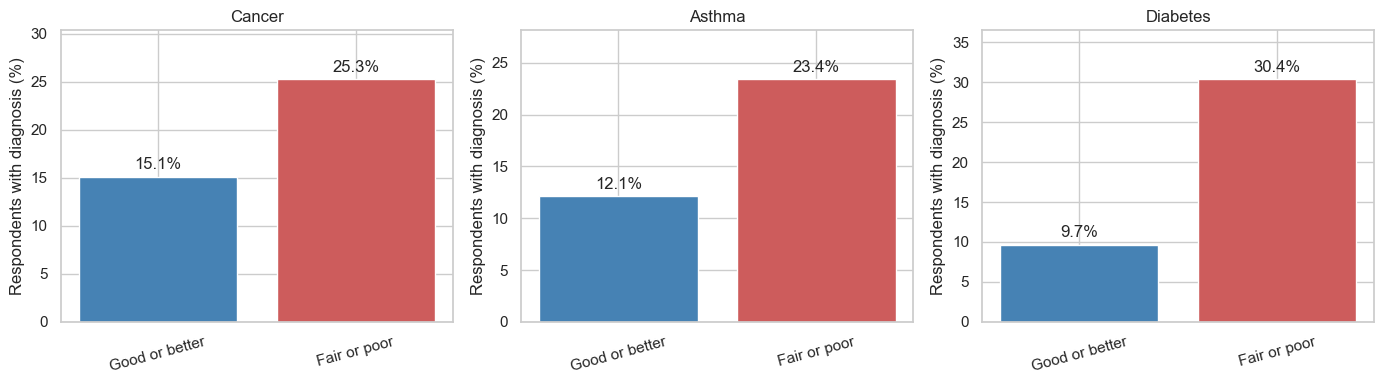

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for axis, disease in zip(
    axes,
    ["cancer", "asthma", "diabetes"],
):
    values = disease_prevalence.loc[disease]

    bars = axis.bar(
        values.index,
        values.values,
        color=["steelblue", "indianred"],
    )

    axis.bar_label(
        bars,
        labels=[f"{value:.1f}%" for value in values],
        padding=3,
    )

    axis.set_title(disease.capitalize())
    axis.set_ylabel("Respondents with diagnosis (%)")
    axis.set_ylim(0, values.max() * 1.2)
    axis.tick_params(axis="x", rotation=15)

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "disease_prevalence_by_target.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

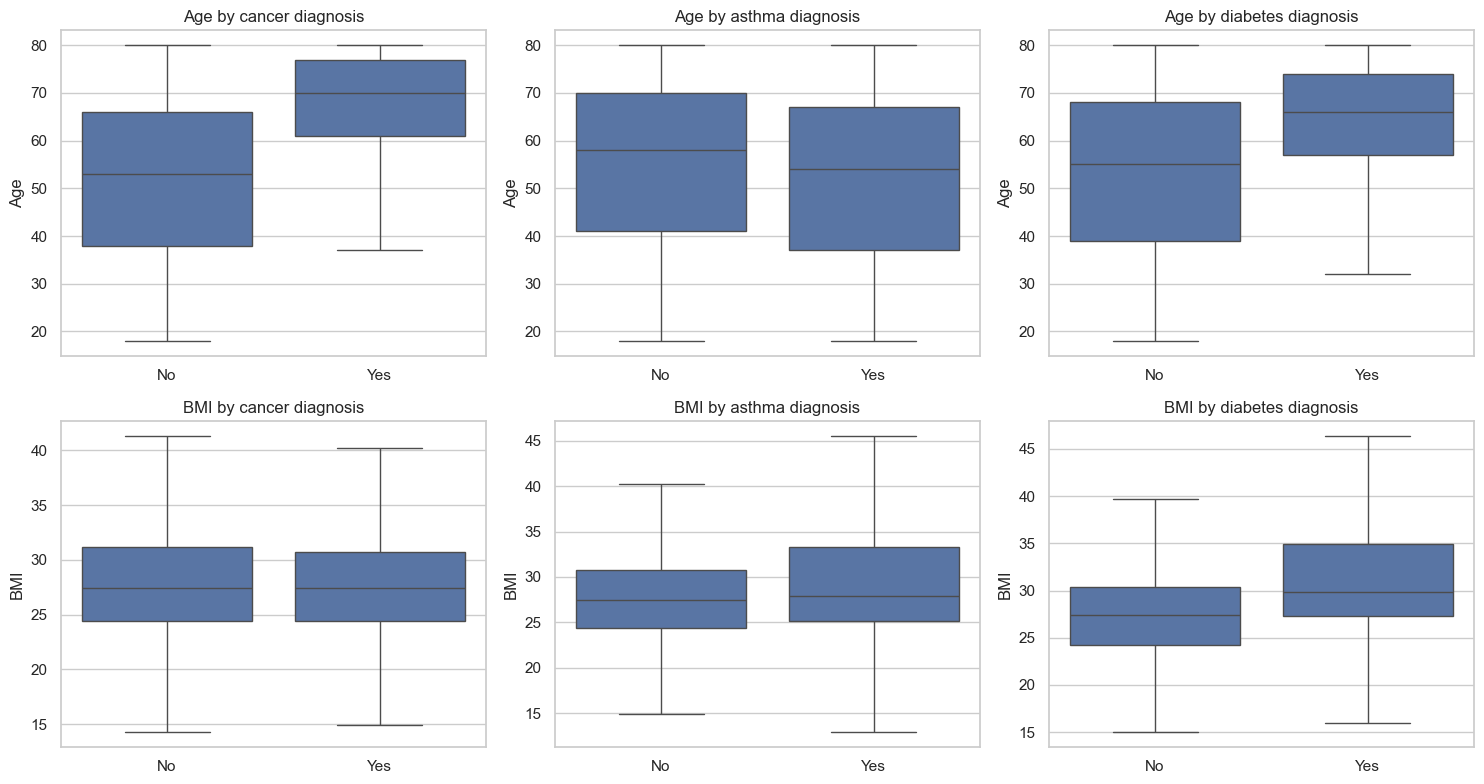

In [34]:
disease_boxplot_data = disease_eda.copy()

disease_boxplot_data["_age"] = df_eda["_age"]
disease_boxplot_data["_bmi"] = df_eda["_bmi"] / 100

diseases = ["cancer", "asthma", "diabetes"]

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 8),
)

for column_index, disease in enumerate(diseases):
    sns.boxplot(
        data=disease_boxplot_data,
        x=disease,
        y="_age",
        ax=axes[0, column_index],
        showfliers=False,
    )

    axes[0, column_index].set_title(
        f"Age by {disease} diagnosis"
    )
    axes[0, column_index].set_xlabel("")
    axes[0, column_index].set_ylabel("Age")
    axes[0, column_index].set_xticks(
        [0, 1],
        labels=["No", "Yes"],
    )

    sns.boxplot(
        data=disease_boxplot_data,
        x=disease,
        y="_bmi",
        ax=axes[1, column_index],
        showfliers=False,
    )

    axes[1, column_index].set_title(
        f"BMI by {disease} diagnosis"
    )
    axes[1, column_index].set_xlabel("")
    axes[1, column_index].set_ylabel("BMI")
    axes[1, column_index].set_xticks(
        [0, 1],
        labels=["No", "Yes"],
    )

plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "age_bmi_by_disease.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [35]:
from matplotlib.ticker import PercentFormatter

categorical_eda_candidates = [
    "_sex",
    "exercise",
    "_smoking_status",
    "income",
    "education",
    "heart_attack",
    "heart_disease",
    "stroke",
    "diabetes",
    "copd",
    "kidney_disease",
    "depression",
]

categorical_eda_features = [
    column
    for column in categorical_eda_candidates
    if column in categorical_features
]

In [36]:
yes_no_labels = {
    -1: "Missing",
    1: "Yes",
    2: "No",
    7: "Don't know",
    9: "Refused",
}

category_labels = {
    "_sex": {
        -1: "Missing",
        1: "Male",
        2: "Female",
    },

    "exercise": yes_no_labels,

    "_smoking_status": {
        -1: "Missing",
        1: "Daily",
        2: "Some days",
        3: "Former",
        4: "Never",
        9: "Unknown/refused",
    },

    "income": {
        -1: "Missing",
        1: "<$10k",
        2: "$10–15k",
        3: "$15–20k",
        4: "$20–25k",
        5: "$25–35k",
        6: "$35–50k",
        7: "$50–75k",
        8: "$75–100k",
        9: "$100–150k",
        10: "$150–200k",
        11: "$200k+",
        77: "Don't know",
        99: "Refused",
    },

    "education": {
        -1: "Missing",
        1: "No school",
        2: "Grades 1–8",
        3: "Grades 9–11",
        4: "High school",
        5: "Some college",
        6: "College degree",
        9: "Refused",
    },

    "heart_attack": yes_no_labels,
    "heart_disease": yes_no_labels,
    "stroke": yes_no_labels,
    "copd": yes_no_labels,
    "kidney_disease": yes_no_labels,
    "depression": yes_no_labels,

    "diabetes": {
        -1: "Missing",
        1: "Diabetes",
        2: "Gestational",
        3: "No",
        4: "Prediabetes",
        7: "Don't know",
        9: "Refused",
    },
}

feature_titles = {
    "_sex": "Sex",
    "exercise": "Physical activity",
    "_smoking_status": "Smoking status",
    "income": "Income",
    "education": "Education",
    "heart_attack": "Heart attack",
    "heart_disease": "Heart disease",
    "stroke": "Stroke",
    "diabetes": "Diabetes",
    "copd": "COPD",
    "kidney_disease": "Kidney disease",
    "depression": "Depression",
}

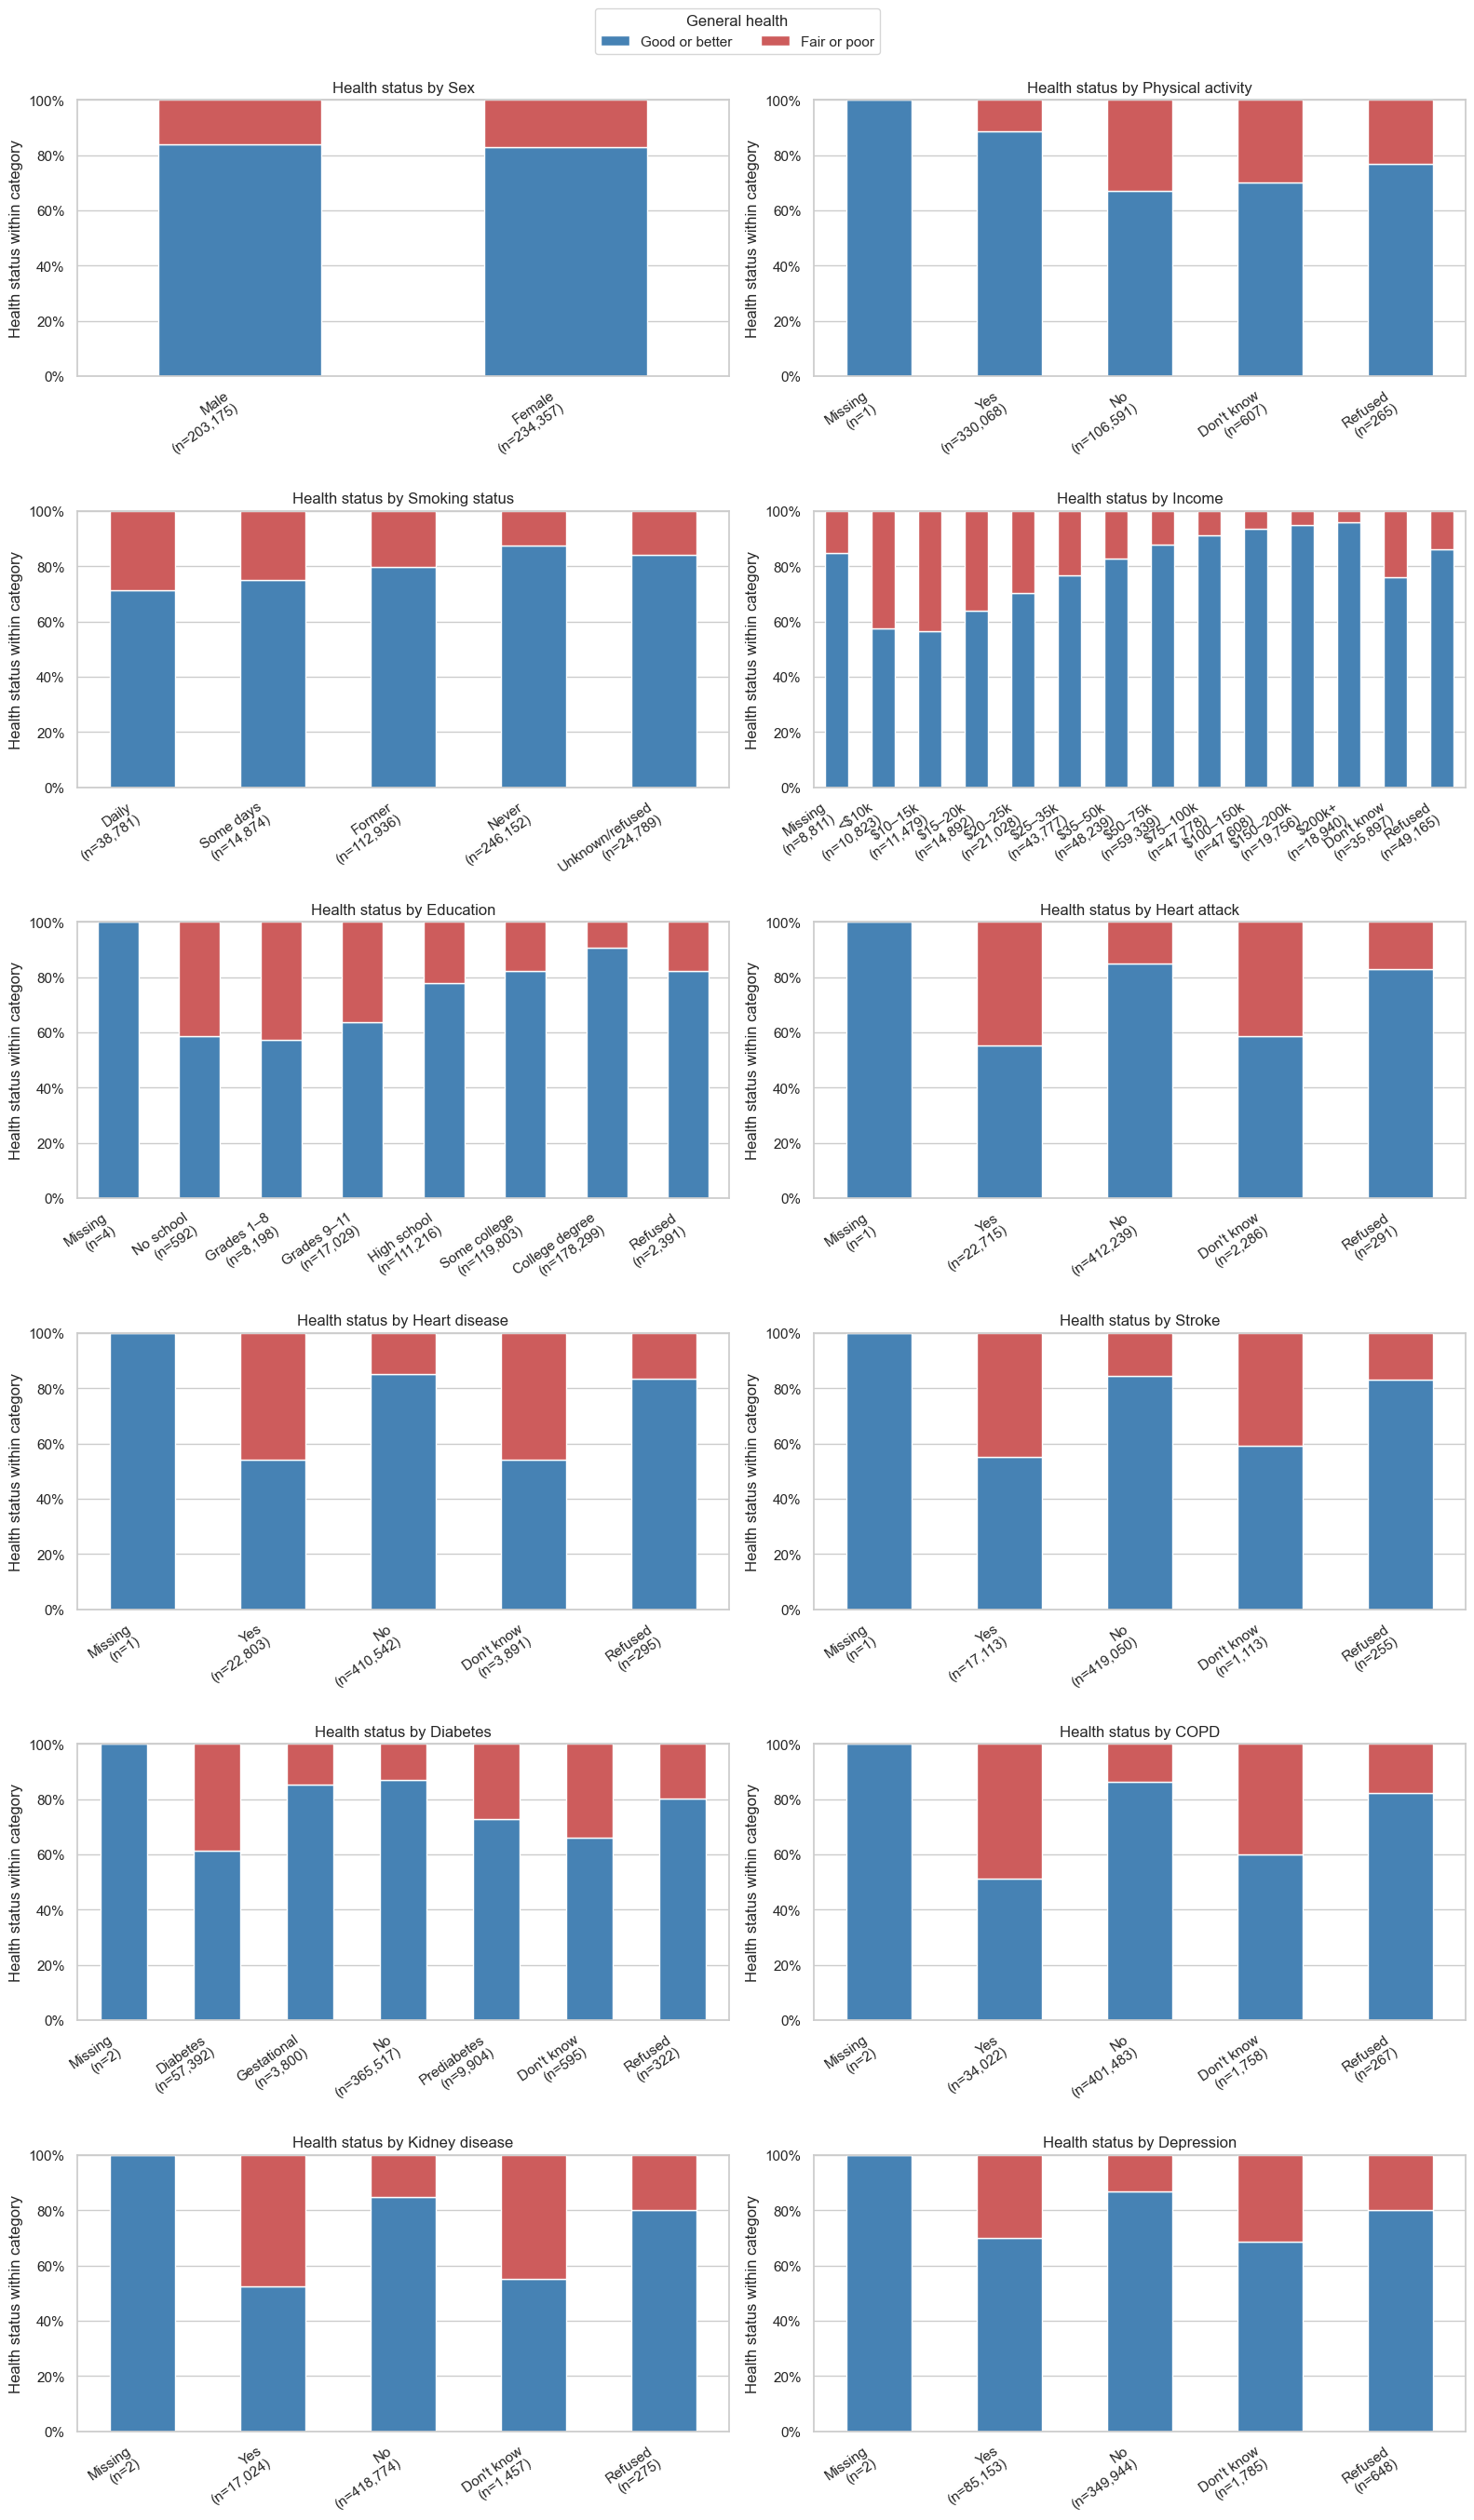

In [37]:
n_columns = 2
n_rows = int(
    np.ceil(len(categorical_eda_features) / n_columns)
)

fig, axes = plt.subplots(
    n_rows,
    n_columns,
    figsize=(16, 4.5 * n_rows),
)

axes = np.atleast_1d(axes).ravel()

for axis, column in zip(
    axes,
    categorical_eda_features,
):
    counts = (
        df_eda[column]
        .value_counts()
        .sort_index()
    )

    comparison = pd.crosstab(
        df_eda[column],
        df_eda["health_binary"],
        normalize="index",
    ).reindex(
        index=counts.index,
        columns=[0, 1],
        fill_value=0,
    )

    comparison.plot(
        kind="bar",
        stacked=True,
        color=["steelblue", "indianred"],
        ax=axis,
        legend=False,
    )

    labels = category_labels[column]

    tick_labels = [
        (
            f"{labels.get(value, str(value))}\n"
            f"(n={counts.loc[value]:,})"
        )
        for value in comparison.index
    ]

    axis.set_xticklabels(
        tick_labels,
        rotation=35,
        ha="right",
    )

    axis.set_title(
        f"Health status by {feature_titles[column]}"
    )
    axis.set_xlabel("")
    axis.set_ylabel("Health status within category")
    axis.set_ylim(0, 1)
    axis.yaxis.set_major_formatter(
        PercentFormatter(1.0)
    )

for axis in axes[len(categorical_eda_features):]:
    axis.remove()

handles, _ = axes[0].get_legend_handles_labels()

fig.legend(
    handles,
    ["Good or better", "Fair or poor"],
    title="General health",
    loc="upper center",
    ncol=2,
    bbox_to_anchor=(0.5, 1.005),
)

plt.tight_layout(rect=[0, 0, 1, 0.98])

plt.savefig(
    RESULTS_DIR / "health_by_categorical_features.png",
    dpi=140,
    bbox_inches="tight",
)

plt.show()

Main findings:
- Sex shows almost no association with the target.
- Without physical activity, the share of Fair or poor health is about three times higher.
- Daily smokers report poor health more often than never-smokers.
- Income and education show pronounced gradients.
- Heart attack, coronary heart disease, stroke, diabetes, COPD and kidney disease are strongly associated with Fair or poor health.
- Depression also shows a noticeable association.

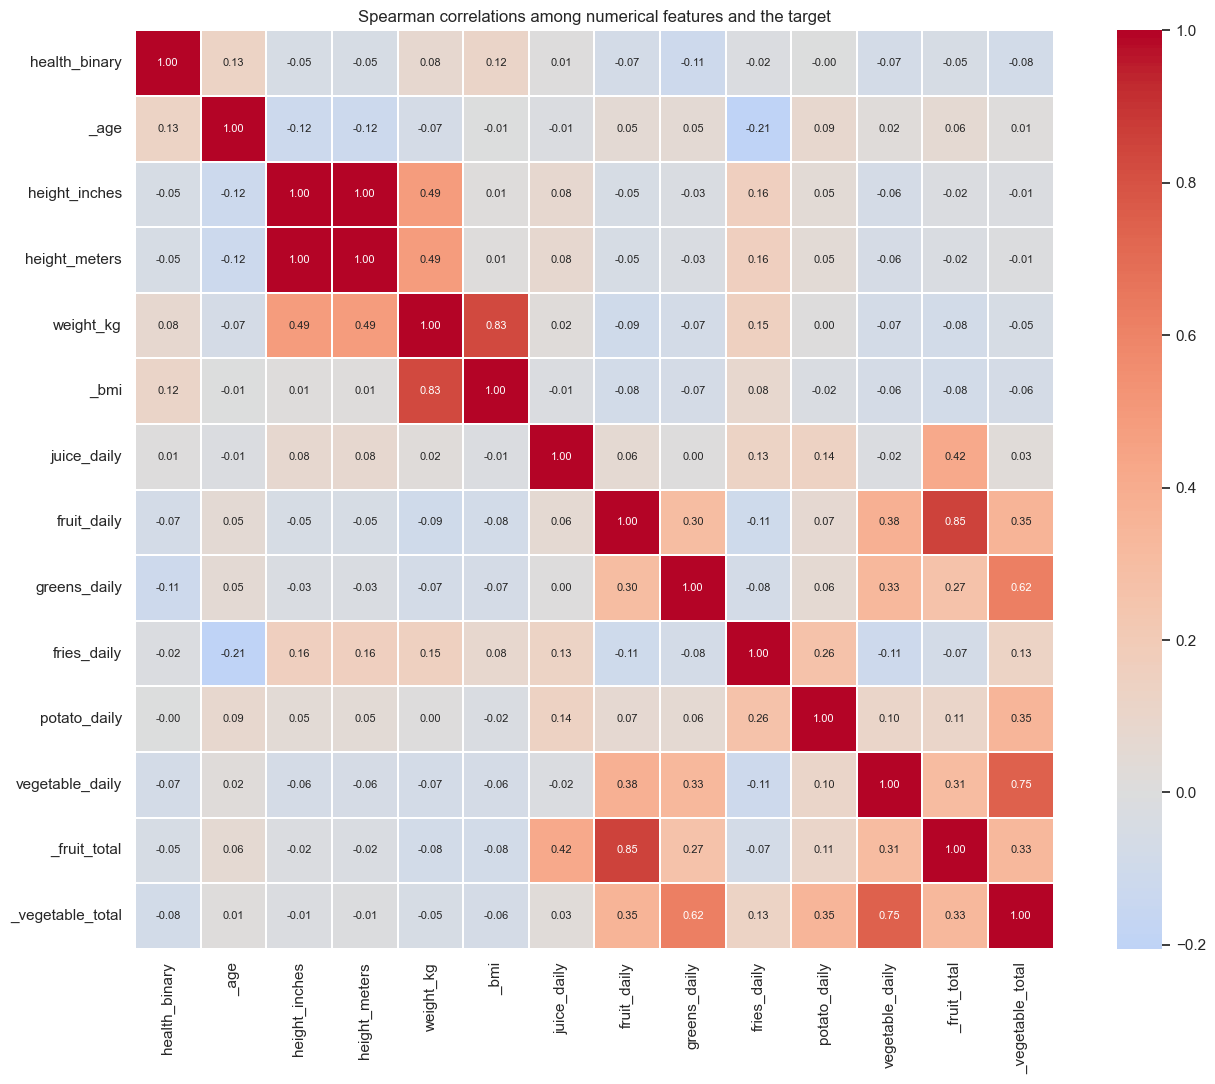

In [38]:
correlation_columns = ["health_binary"] + numerical_features
correlation_matrix = eda_numeric[correlation_columns].corr(method="spearman")

plt.figure(figsize=(14, 11))
sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    square=True,
    linewidths=0.3,
    annot_kws={"size": 8},
)
plt.title("Spearman correlations among numerical features and the target")
plt.tight_layout()
plt.savefig(
    RESULTS_DIR / "numerical_correlations.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

Numerical features correlate only weakly with the binary target. The strongest correlations are:
- age: 0.13;
- BMI: 0.12;
- leafy greens: −0.11;
- weight: 0.08;
- total vegetable consumption: −0.08.

A positive coefficient indicates association with the Fair or poor class; a negative one indicates association with Good or better.
A weak individual correlation does not mean that a feature is useless: relationships may be nonlinear or appear only jointly with other features.

height_inches and height_meters: correlation 1.00, so only one should be kept; height_meters is the more natural choice.
fruit_daily and _fruit_total: 0.85.
vegetable_daily and _vegetable_total: 0.75.
greens_daily and _vegetable_total: 0.62.
weight_kg and _bmi: 0.83, but they are not exact duplicates, because BMI also takes height into account, so both are kept for now.

In [39]:
df_eda = df_eda.drop(columns=["height_inches"])
eda_numeric = eda_numeric.drop(columns=["height_inches"])

In [40]:
df = df.drop(columns=["height_inches"])
numerical_features.remove("height_inches")

## X/y splitting

In [41]:
X = df.drop(columns=["health", "health_binary"]).copy()
y = df["health_binary"].copy()

print("Features shape:", X.shape)
print("Target shape:", y.shape)
display(y.value_counts().sort_index().rename("count").to_frame())

Features shape: (437532, 108)
Target shape: (437532,)


,count
health_binary,
0,364791
1,72741


In [42]:
X_model = X.copy()

NUMERIC_FEATURES = [
    column
    for column in numerical_features
    if column in X_model.columns
]

CATEGORICAL_FEATURES = [
    column
    for column in X_model.columns
    if column not in NUMERIC_FEATURES
]

print("Numerical features:", NUMERIC_FEATURES)
print("Number of categorical features:", len(CATEGORICAL_FEATURES))
print("Total number of predictors:", X_model.shape[1])

Numerical features: ['_age', 'height_meters', 'weight_kg', '_bmi', 'juice_daily', 'fruit_daily', 'greens_daily', 'fries_daily', 'potato_daily', 'vegetable_daily', '_fruit_total', '_vegetable_total']
Number of categorical features: 96
Total number of predictors: 108


## Feature preprocessing, classifiers, folds, and evaluation

Due to computational constraints, exploratory model and feature comparisons use stratified 2-fold cross-validation. The final statistical comparison of the two selected models uses paired stratified 10-fold cross-validation.

In [43]:
def build_preprocessor(data, extra_numeric_features=None):
    numeric_features = NUMERIC_FEATURES.copy()

    if extra_numeric_features is not None:
        numeric_features += extra_numeric_features

    numeric_features = [column for column in numeric_features if column in data.columns]
    categorical_features = [column for column in data.columns if column not in numeric_features]

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="constant", fill_value=-1)),
        ("one_hot", OneHotEncoder(handle_unknown="ignore", sparse_output=True, dtype=np.float32)),
    ])

    return ColumnTransformer(
        transformers=[
            ("numeric", numeric_pipeline, numeric_features),
            ("categorical", categorical_pipeline, categorical_features),
        ],
        sparse_threshold=1.0,
    )

In [44]:
def make_models(balanced=False):
    class_weight = "balanced" if balanced else None
    catboost_balance = "Balanced" if balanced else None

    return {
        "logistic_regression": LogisticRegression(
            C=1.0, solver="saga", max_iter=1000, tol=1e-3, class_weight=class_weight,
            random_state=RANDOM_STATE, n_jobs=1,
        ),
        "decision_tree": DecisionTreeClassifier(
            max_depth=15, min_samples_leaf=20, class_weight=class_weight,
            random_state=RANDOM_STATE,
        ),
        "random_forest": RandomForestClassifier(
            n_estimators=100, min_samples_leaf=5, max_features="sqrt",
            class_weight=class_weight, random_state=RANDOM_STATE, n_jobs=2,
        ),
        "linear_svc": LinearSVC(
            C=1.0, class_weight=class_weight, random_state=RANDOM_STATE, dual="auto",
        ),
        "catboost": CatBoostClassifier(
            iterations=300, depth=6, learning_rate=0.1, loss_function="Logloss",
            eval_metric="AUC", auto_class_weights=catboost_balance,
            random_seed=RANDOM_STATE, thread_count=4, verbose=False,
            allow_writing_files=False,
        ),
    }

In [45]:
cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE)
cv_splits = list(cv.split(X_model, y))

def prediction_scores(model, X_data):
    if hasattr(model, "predict_proba"):
        return model.predict_proba(X_data)[:, 1]
    return model.decision_function(X_data)

def summarize_results(results):
    metric_columns = [
        "roc_auc", "pr_auc", "f1", "precision", "recall",
        "balanced_accuracy", "fit_time_seconds", "output_features",
    ]
    summary = results.groupby(["experiment", "model"])[metric_columns].agg(["mean", "std"])
    return summary.sort_values(("roc_auc", "mean"), ascending=False)

In [46]:
def evaluate_models(X_data, y_data, feature_transformer, models, experiment_name):
    fold_rows = []
    experiment_started = perf_counter()

    print(
        f"[{datetime.now():%H:%M:%S}] "
        f"{experiment_name}: experiment started",
        flush=True,
    )

    for fold, (train_index, validation_index) in enumerate(cv_splits, start=1):
        fold_started = perf_counter()

        print(
            f"\n[{datetime.now():%H:%M:%S}] "
            f"{experiment_name}: fold {fold}/{len(cv_splits)} — preprocessing...",
            flush=True,
        )

        X_train = X_data.iloc[train_index]
        X_validation = X_data.iloc[validation_index]
        y_train = y_data.iloc[train_index]
        y_validation = y_data.iloc[validation_index]

        transformer = clone(feature_transformer)

        preprocessing_started = perf_counter()
        X_train_transformed = transformer.fit_transform(X_train, y_train)
        X_validation_transformed = transformer.transform(X_validation)
        preprocessing_time = perf_counter() - preprocessing_started

        print(
            f"[{datetime.now():%H:%M:%S}] "
            f"Preprocessing completed in {preprocessing_time:.1f} sec",
            flush=True,
        )

        for model_name, model_template in models.items():
            model = clone(model_template)

            print(
                f"[{datetime.now():%H:%M:%S}] "
                f"{model_name}: training...",
                flush=True,
            )

            training_started = perf_counter()
            model.fit(X_train_transformed, y_train)
            fit_time = perf_counter() - training_started

            print(
                f"[{datetime.now():%H:%M:%S}] "
                f"{model_name}: training completed in {fit_time / 60:.1f} min; testing...",
                flush=True,
            )

            testing_started = perf_counter()
            y_pred = model.predict(X_validation_transformed)
            y_score = prediction_scores(model, X_validation_transformed)
            testing_time = perf_counter() - testing_started

            print(
                f"[{datetime.now():%H:%M:%S}] "
                f"{model_name}: testing completed in {testing_time:.1f} sec",
                flush=True,
            )

            tn, fp, fn, tp = confusion_matrix(y_validation, y_pred, labels=[0, 1]).ravel()

            fold_rows.append({
                "experiment": experiment_name,
                "model": model_name,
                "fold": fold,
                "roc_auc": roc_auc_score(y_validation, y_score),
                "pr_auc": average_precision_score(y_validation, y_score),
                "f1": f1_score(y_validation, y_pred, zero_division=0),
                "precision": precision_score(y_validation, y_pred, zero_division=0),
                "recall": recall_score(y_validation, y_pred, zero_division=0),
                "balanced_accuracy": balanced_accuracy_score(y_validation, y_pred),
                "tn": tn,
                "fp": fp,
                "fn": fn,
                "tp": tp,
                "fit_time_seconds": fit_time,
                "output_features": X_train_transformed.shape[1],
            })

        del X_train_transformed, X_validation_transformed
        gc.collect()

        fold_time = perf_counter() - fold_started

        print(
            f"[{datetime.now():%H:%M:%S}] "
            f"{experiment_name}: fold {fold}/{len(cv_splits)} completed "
            f"in {fold_time / 60:.1f} min",
            flush=True,
        )

    experiment_time = perf_counter() - experiment_started

    print(
        f"\n[{datetime.now():%H:%M:%S}] "
        f"{experiment_name}: experiment completed "
        f"in {experiment_time / 60:.1f} min",
        flush=True,
    )

    results = pd.DataFrame(fold_rows)
    results["experiment_time_seconds"] = experiment_time
    return results

In [47]:
full_transformer = Pipeline([("preprocessing", build_preprocessor(X_model))])

fitted_full_transformer = clone(full_transformer).fit(X_model, y)
full_feature_names = fitted_full_transformer.named_steps["preprocessing"].get_feature_names_out()

print("Features before preprocessing:", X_model.shape[1])
print("Features after one-hot encoding:", len(full_feature_names))

Features before preprocessing: 108
Features after one-hot encoding: 937


## Dummy baseline

In [48]:
dummy_transformer = Pipeline([("identity", "passthrough")])

dummy_results = evaluate_models(
    X_model, y, dummy_transformer,
    {"dummy": DummyClassifier(strategy="prior")},
    "dummy_full",
)

display(summarize_results(dummy_results))
dummy_results.to_csv(RESULTS_DIR / "results_dummy.csv", index=False)

[17:48:12] dummy_full: experiment started

[17:48:12] dummy_full: fold 1/2 — preprocessing...
[17:48:12] Preprocessing completed in 0.0 sec
[17:48:12] dummy: training...
[17:48:12] dummy: training completed in 0.0 min; testing...
[17:48:12] dummy: testing completed in 0.0 sec
[17:48:12] dummy_full: fold 1/2 completed in 0.0 min

[17:48:12] dummy_full: fold 2/2 — preprocessing...
[17:48:12] Preprocessing completed in 0.0 sec
[17:48:12] dummy: training...
[17:48:12] dummy: training completed in 0.0 min; testing...
[17:48:12] dummy: testing completed in 0.0 sec
[17:48:13] dummy_full: fold 2/2 completed in 0.0 min

[17:48:13] dummy_full: experiment completed in 0.0 min


roc_auc         pr_auc             f1      precision       \
                    mean  std      mean       std mean  std      mean  std   
experiment model                                                             
dummy_full dummy     0.5  0.0  0.166253  0.000003  0.0  0.0       0.0  0.0   

                 recall      balanced_accuracy      fit_time_seconds  \
                   mean  std              mean  std             mean   
experiment model                                                       
dummy_full dummy    0.0  0.0               0.5  0.0          0.00526   

                           output_features       
                       std            mean  std  
experiment model                                 
dummy_full dummy  0.000996           108.0  0.0

ROC-AUC = 0.5: the Dummy classifier does not distinguish between the classes.
PR-AUC (average precision) = 0.1663: approximately equal to the share of the positive class (Fair or poor) in the dataset.
F1 = 0, precision = 0, recall = 0: the model always predicts the more frequent class, Good or better.
balanced_accuracy = 0.5: the result of a random classifier.
All subsequent models should clearly outperform this baseline.

# Experiment 1. Full feature set

We use all meaningful features after data cleaning and NaN handling

In [49]:
full_results = evaluate_models(X_model, y, full_transformer, make_models(balanced=False), "full")

display(summarize_results(full_results))
full_results.to_csv(RESULTS_DIR / "results_full.csv", index=False)

[17:48:13] full: experiment started

[17:48:13] full: fold 1/2 — preprocessing...
[17:48:16] Preprocessing completed in 3.1 sec
[17:48:16] logistic_regression: training...
[17:49:44] logistic_regression: training completed in 1.5 min; testing...
[17:49:44] logistic_regression: testing completed in 0.2 sec
[17:49:45] decision_tree: training...
[17:50:16] decision_tree: training completed in 0.5 min; testing...
[17:50:16] decision_tree: testing completed in 0.3 sec
[17:50:16] random_forest: training...
[17:53:11] random_forest: training completed in 2.9 min; testing...
[17:53:15] random_forest: testing completed in 4.5 sec
[17:53:16] linear_svc: training...
[17:54:22] linear_svc: training completed in 1.1 min; testing...
[17:54:22] linear_svc: testing completed in 0.1 sec
[17:54:23] catboost: training...
[17:54:33] catboost: training completed in 0.2 min; testing...
[17:54:34] catboost: testing completed in 0.8 sec
[17:54:34] full: fold 1/2 completed in 6.4 min

[17:54:34] full: fold 2/2

roc_auc              pr_auc            \
                                    mean       std      mean       std   
experiment model                                                         
full       catboost             0.901803  0.000975  0.698460  0.000137   
           logistic_regression  0.898398  0.000975  0.690095  0.000204   
           linear_svc           0.898105  0.000900  0.691583  0.000284   
           random_forest        0.896996  0.000485  0.686779  0.000048   
           decision_tree        0.861175  0.001279  0.609515  0.000939   

                                      f1           precision            \
                                    mean       std      mean       std   
experiment model                                                         
full       catboost             0.610951  0.002208  0.731282  0.000378   
           logistic_regression  0.602999  0.000622  0.734767  0.001303   
           linear_svc           0.592435  0.000602  0.744128  0.001301   
           random_forest        0.572187  0.001946  0.759549  0.002467   
           decision_tree        0.553636  0.002143  0.666463  0.007327   

                                  recall           balanced_accuracy  \
                                    mean       std              mean   
experiment model                                                       
full       catboost             0.524628  0.003062          0.743094   
           logistic_regression  0.511307  0.001526          0.737251   
           linear_svc           0.492116  0.000262          0.729187   
           random_forest        0.458971  0.001603          0.714999   
           decision_tree        0.473543  0.006834          0.713133   

                                         fit_time_seconds             \
                                     std             mean        std   
experiment model                                                       
full       catboost             0.001455        10.737366   0.092456   
           logistic_regression  0.000585        63.691544  35.196649   
           linear_svc           0.000238        69.751122   4.239776   
           random_forest        0.000947       177.214285   3.279257   
           decision_tree        0.002297        31.265252   0.177881   

                               output_features            
                                          mean       std  
experiment model                                          
full       catboost                      877.5  21.92031  
           logistic_regression           877.5  21.92031  
           linear_svc                    877.5  21.92031  
           random_forest                 877.5  21.92031  
           decision_tree                 877.5  21.92031

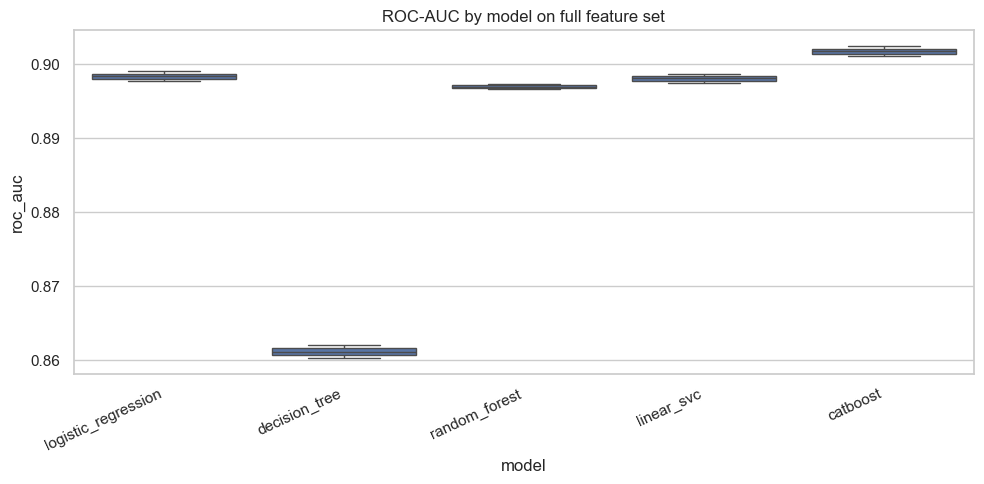

In [50]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=full_results, x="model", y="roc_auc")
plt.xticks(rotation=25, ha="right")
plt.title("ROC-AUC by model on full feature set")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "full_roc_auc_boxplot.png", dpi=160, bbox_inches="tight")
plt.show()

CatBoost achieved the best overall performance on the full feature set, with ROC-AUC 0.9018, PR-AUC 0.6985, F1-score 0.6110, recall 0.5246, and balanced accuracy 0.7431. It was also the fastest classifier, requiring approximately 11 seconds per fold.

Logistic Regression and LinearSVC achieved similar ROC-AUC values of 0.8984 and 0.8981, respectively, while Random Forest reached 0.8970. Random Forest produced the highest precision (0.7595) but lower recall (0.4590), meaning that it predicted fair or poor health less frequently but was more often correct when doing so. Decision Tree performed substantially worse, with ROC-AUC 0.8612.

# Experiment 2. Basic feature selection with SelectKBest

Hypothesis: a compact subset dominated by age, physical and mental health, chronic conditions, functional limitations, and socioeconomic variables will preserve most of the predictive performance. Dietary variables and specialized survey variables are expected to contribute less.

In [51]:
select_k_transformer = Pipeline([
    ("preprocessing", build_preprocessor(X_model)),
    ("select_k_best", SelectKBest(score_func=f_classif, k=100)),
])

select_k_results = evaluate_models(X_model, y, select_k_transformer, make_models(balanced=False), "select_k_best")

display(summarize_results(select_k_results))
select_k_results.to_csv(RESULTS_DIR / "results_select_k_best.csv", index=False)

[18:00:18] select_k_best: experiment started

[18:00:18] select_k_best: fold 1/2 — preprocessing...
[18:00:22] Preprocessing completed in 3.7 sec
[18:00:22] logistic_regression: training...
[18:00:34] logistic_regression: training completed in 0.2 min; testing...
[18:00:34] logistic_regression: testing completed in 0.0 sec
[18:00:34] decision_tree: training...
[18:00:42] decision_tree: training completed in 0.1 min; testing...
[18:00:42] decision_tree: testing completed in 0.1 sec
[18:00:42] random_forest: training...
[18:02:49] random_forest: training completed in 2.1 min; testing...
[18:02:52] random_forest: testing completed in 3.2 sec
[18:02:52] linear_svc: training...
[18:02:56] linear_svc: training completed in 0.1 min; testing...
[18:02:56] linear_svc: testing completed in 0.0 sec
[18:02:56] catboost: training...
[18:03:01] catboost: training completed in 0.1 min; testing...
[18:03:01] catboost: testing completed in 0.3 sec
[18:03:01] select_k_best: fold 1/2 completed in 2.7 min

roc_auc              pr_auc            \
                                       mean       std      mean       std   
experiment    model                                                         
select_k_best catboost             0.895615  0.000937  0.688002  0.000551   
              linear_svc           0.891517  0.000621  0.680905  0.000690   
              random_forest        0.890962  0.000762  0.678756  0.000201   
              logistic_regression  0.890812  0.000890  0.679282  0.001337   
              decision_tree        0.868568  0.001881  0.623172  0.001231   

                                         f1           precision            \
                                       mean       std      mean       std   
experiment    model                                                         
select_k_best catboost             0.599748  0.002188  0.730822  0.000014   
              linear_svc           0.576000  0.000947  0.748477  0.000539   
              random_forest        0.585637  0.000771  0.734695  0.001669   
              logistic_regression  0.587049  0.003286  0.733957  0.001496   
              decision_tree        0.562768  0.000681  0.678867  0.002505   

                                     recall           balanced_accuracy  \
                                       mean       std              mean   
experiment    model                                                       
select_k_best catboost             0.508544  0.003140          0.735597   
              linear_svc           0.468127  0.001041          0.718379   
              random_forest        0.486864  0.001799          0.725903   
              logistic_regression  0.489146  0.003898          0.726896   
              decision_tree        0.480582  0.000263          0.717624   

                                            fit_time_seconds            \
                                        std             mean       std   
experiment    model                                                      
select_k_best catboost             0.001455         5.003550  0.102015   
              linear_svc           0.000530         2.960049  0.493619   
              random_forest        0.000684       128.996799  2.784089   
              logistic_regression  0.001943         9.231042  3.786679   
              decision_tree        0.000142         8.374352  0.356964   

                                  output_features       
                                             mean  std  
experiment    model                                     
select_k_best catboost                      100.0  0.0  
              linear_svc                    100.0  0.0  
              random_forest                 100.0  0.0  
              logistic_regression           100.0  0.0  
              decision_tree                 100.0  0.0

In [52]:
select_k_fitted = clone(select_k_transformer).fit(X_model, y)
preprocessed_names = select_k_fitted.named_steps["preprocessing"].get_feature_names_out()
selected_k_names = preprocessed_names[select_k_fitted.named_steps["select_k_best"].get_support()]

display(pd.Series(selected_k_names, name="selected_feature").to_frame())

,selected_feature
0,numeric___age
1,numeric___bmi
2,categorical__physical_days_15.0
3,categorical__physical_days_20.0
4,categorical__physical_days_30.0
5,categorical__physical_days_88.0
6,categorical__mental_days_30.0
7,categorical__mental_days_88.0
8,categorical__limited_days_-1.0
9,categorical__limited_days_15.0


SelectKBest reduced the feature space from approximately 878 encoded features to 100. The total experiment time decreased from 12.1 to 5.4 minutes, approximately a 2.2-fold reduction, although the strongest models lost some predictive performance.

For CatBoost, feature selection caused a small decrease in predictive performance but reduced training time by approximately half. Logistic Regression and LinearSVC showed a similar moderate loss in ROC-AUC, while becoming substantially faster. This indicates that the removed features contained some useful information, but much of it was redundant.

Random Forest also lost some ROC-AUC, but improved its F1-score, recall, and balanced accuracy, suggesting a better balance between the two target classes. Decision Tree was the only model that improved consistently after feature selection, indicating that simpler and less stable models benefit more from removing weak or noisy features.

The selected features mainly represented age and BMI; physically and mentally unhealthy days; limitations in daily activities; physical activity; cardiovascular and chronic diseases; functional limitations; education, income, and employment; smoking and alcohol use; and access to healthcare. The selected `limited_days_-1.0` indicator shows that a missing response for this variable also contained predictive information.

# Experiment 3. Dimensionality reduction with TruncatedSVD

TruncatedSVD is used instead of PCA because one-hot encoding produces a sparse matrix.

In [53]:
svd_transformer = Pipeline([
    ("preprocessing", build_preprocessor(X_model)),
    ("svd", TruncatedSVD(n_components=100, random_state=RANDOM_STATE)),
])

svd_results = evaluate_models(X_model, y, svd_transformer, make_models(balanced=False), "svd")

display(summarize_results(svd_results))
svd_results.to_csv(RESULTS_DIR / "results_svd.csv", index=False)

[18:05:48] svd: experiment started

[18:05:48] svd: fold 1/2 — preprocessing...
[18:06:03] Preprocessing completed in 14.6 sec
[18:06:03] logistic_regression: training...
[18:06:04] logistic_regression: training completed in 0.0 min; testing...
[18:06:04] logistic_regression: testing completed in 0.0 sec
[18:06:05] decision_tree: training...
[18:06:35] decision_tree: training completed in 0.5 min; testing...
[18:06:35] decision_tree: testing completed in 0.1 sec
[18:06:35] random_forest: training...
[18:09:30] random_forest: training completed in 2.9 min; testing...
[18:09:33] random_forest: testing completed in 2.8 sec
[18:09:33] linear_svc: training...
[18:09:38] linear_svc: training completed in 0.1 min; testing...
[18:09:38] linear_svc: testing completed in 0.0 sec
[18:09:38] catboost: training...
[18:09:46] catboost: training completed in 0.1 min; testing...
[18:09:47] catboost: testing completed in 0.2 sec
[18:09:47] svd: fold 1/2 completed in 4.0 min

[18:09:47] svd: fold 2/2 — 

roc_auc              pr_auc            \
                                    mean       std      mean       std   
experiment model                                                         
svd        linear_svc           0.895822  0.000733  0.685219  0.000161   
           logistic_regression  0.895312  0.000912  0.683773  0.000689   
           catboost             0.894020  0.001045  0.681425  0.000027   
           random_forest        0.884287  0.000801  0.659177  0.000995   
           decision_tree        0.799143  0.004634  0.507213  0.005693   

                                      f1           precision            \
                                    mean       std      mean       std   
experiment model                                                         
svd        linear_svc           0.582060  0.001211  0.744813  0.000312   
           logistic_regression  0.590862  0.000360  0.733040  0.001258   
           catboost             0.591170  0.000820  0.728496  0.001410   
           random_forest        0.517205  0.000037  0.766654  0.001759   
           decision_tree        0.492075  0.000230  0.573563  0.003180   

                                  recall           balanced_accuracy  \
                                    mean       std              mean   
experiment model                                                       
svd        linear_svc           0.477681  0.001760          0.722523   
           logistic_regression  0.494879  0.001079          0.729470   
           catboost             0.497409  0.001818          0.730221   
           random_forest        0.390234  0.000498          0.683275   
           decision_tree        0.430871  0.002147          0.683494   

                                         fit_time_seconds            \
                                     std             mean       std   
experiment model                                                      
svd        linear_svc           0.000793         4.246865  0.340712   
           logistic_regression  0.000384         1.871993  0.210788   
           catboost             0.000709         8.584761  0.163003   
           random_forest        0.000117       177.250059  3.039968   
           decision_tree        0.000500        30.286974  0.020343   

                               output_features       
                                          mean  std  
experiment model                                     
svd        linear_svc                    100.0  0.0  
           logistic_regression           100.0  0.0  
           catboost                      100.0  0.0  
           random_forest                 100.0  0.0  
           decision_tree                 100.0  0.0

With 100 components, TruncatedSVD substantially reduced the feature space but produced lower performance than the full representation.

For CatBoost:
- full feature set: ROC-AUC 0.9018;
- SelectKBest with 100 features: ROC-AUC 0.8956;
- TruncatedSVD with 100 components: ROC-AUC 0.8940.

LinearSVC achieved the best ROC-AUC with SVD, reaching 0.8958. This suggests that the dense lower-dimensional representation is more suitable for linear models than for tree-based models.

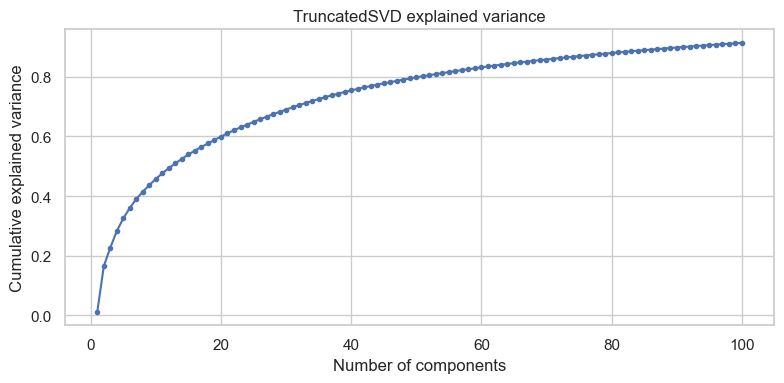

In [54]:
svd_fitted = clone(svd_transformer).fit(X_model, y)
svd_model = svd_fitted.named_steps["svd"]
cumulative_variance = np.cumsum(svd_model.explained_variance_ratio_)

plt.figure(figsize=(8, 4))
plt.plot(np.arange(1, len(cumulative_variance) + 1), cumulative_variance, marker="o", markersize=3)
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance")
plt.title("TruncatedSVD explained variance")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "svd_explained_variance.png", dpi=160, bbox_inches="tight")
plt.show()

The explained-variance curve increases smoothly without a clear elbow. Approximately 50 components explain 80% of the variance, while 100 components explain about 91%.

In [55]:
svd_input_names = svd_fitted.named_steps["preprocessing"].get_feature_names_out()

for component_index in range(3):
    top_indices = np.argsort(np.abs(svd_model.components_[component_index]))[-15:][::-1]

    display(pd.DataFrame({
        "feature": svd_input_names[top_indices],
        "loading": svd_model.components_[component_index, top_indices],
    }).style.set_caption(f"Component {component_index + 1}"))

,feature,loading
0,categorical___fruit_excess_1.0,0.130871
1,categorical___vegetable_excess_1.0,0.130566
2,categorical__stroke_2.0,0.126384
3,categorical__kidney_disease_2.0,0.126247
4,categorical__heart_attack_2.0,0.124512
5,categorical__heart_disease_2.0,0.123993
6,categorical__dressing_difficulty_2.0,0.123100
7,categorical__smokeless_tobacco_3.0,0.123012
8,categorical__cost_barrier_2.0,0.122247
9,categorical__blind_2.0,0.122078


,feature,loading
0,numeric__missingindicator_fries_daily,0.295472
1,numeric__missingindicator_greens_daily,0.295392
2,numeric__missingindicator_juice_daily,0.292121
3,numeric__missingindicator_potato_daily,0.291633
4,numeric__missingindicator_vegetable_daily,0.290673
5,numeric__missingindicator_fruit_daily,0.289223
6,numeric__missingindicator__fruit_total,0.287741
7,numeric__missingindicator__vegetable_total,0.282397
8,numeric__missingindicator_height_meters,0.188746
9,numeric__missingindicator__bmi,0.162868


,feature,loading
0,numeric___age,0.440345
1,categorical___age_group_6.0,0.197073
2,categorical___age65_group_2.0,0.195063
3,categorical___age65_group_1.0,-0.192781
4,categorical___insured_under65_9.0,0.189082
5,categorical___insured_under65_1.0,-0.165220
6,categorical__employment_7.0,0.158496
7,categorical__insurance_3.0,0.153113
8,categorical__arthritis_1.0,0.145039
9,categorical___arthritis_1.0,0.145039


Component 1 reflects the most common response profile:
- no stroke, kidney disease, heart attack, COPD or functional limitations;
- health insurance coverage;
- no financial barrier to medical care;
- common values of CDC-calculated features.
This is the general profile of a relatively healthy respondent.

Component 2 almost entirely describes the missing-value structure:
- missing values in dietary variables;
- missing BMI, weight and height;
- related CDC indicators of missing or excluded responses.
Thus SVD detected a separate questionnaire-completeness pattern rather than a clinical condition. This is a useful finding: the missing-value structure is meaningful.

Component 3 is associated with age and age-related conditions:
- age and age groups;
- arthritis;
- activity and work limitations;
- insurance;
- employment;
- pneumonia vaccination.
Here, positive and negative loadings define opposite sides of the age and functional profile.

# Experiment 4. Advanced feature selection with RFECV

RFECV selects the final subset using internal stratified two-fold cross-validation.

In [56]:
rfecv_transformer = Pipeline([
    ("preprocessing", build_preprocessor(X_model)),
    ("select_k_best", SelectKBest(score_func=f_classif, k=200)),
    ("rfecv", RFECV(
        estimator=LogisticRegression(C=1.0, solver="saga", max_iter=1000, tol=1e-3, random_state=RANDOM_STATE),
        step=20,
        min_features_to_select=80,
        cv=StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE),
        scoring="roc_auc",
        n_jobs=2,
    )),
])

rfecv_results = evaluate_models(X_model, y, rfecv_transformer, make_models(balanced=False), "rfecv")

display(summarize_results(rfecv_results))
rfecv_results.to_csv(RESULTS_DIR / "results_rfecv.csv", index=False)

[18:14:20] rfecv: experiment started

[18:14:20] rfecv: fold 1/2 — preprocessing...
[18:16:03] Preprocessing completed in 103.6 sec
[18:16:03] logistic_regression: training...
[18:16:23] logistic_regression: training completed in 0.3 min; testing...
[18:16:23] logistic_regression: testing completed in 0.1 sec
[18:16:23] decision_tree: training...
[18:16:39] decision_tree: training completed in 0.3 min; testing...
[18:16:39] decision_tree: testing completed in 0.1 sec
[18:16:40] random_forest: training...
[18:19:33] random_forest: training completed in 2.9 min; testing...
[18:19:36] random_forest: testing completed in 3.5 sec
[18:19:37] linear_svc: training...
[18:19:43] linear_svc: training completed in 0.1 min; testing...
[18:19:43] linear_svc: testing completed in 0.0 sec
[18:19:43] catboost: training...
[18:19:49] catboost: training completed in 0.1 min; testing...
[18:19:50] catboost: testing completed in 0.4 sec
[18:19:50] rfecv: fold 1/2 completed in 5.5 min

[18:19:50] rfecv: fo

roc_auc              pr_auc            \
                                    mean       std      mean       std   
experiment model                                                         
rfecv      catboost             0.900385  0.000759  0.695333  0.000492   
           linear_svc           0.897641  0.000737  0.690111  0.000143   
           logistic_regression  0.897277  0.001008  0.688067  0.000531   
           random_forest        0.895943  0.000422  0.685544  0.000815   
           decision_tree        0.865735  0.001316  0.619821  0.000311   

                                      f1           precision            \
                                    mean       std      mean       std   
experiment model                                                         
rfecv      catboost             0.608554  0.001088  0.728263  0.001469   
           linear_svc           0.589326  0.000015  0.746671  0.001628   
           logistic_regression  0.598980  0.001654  0.734642  0.000790   
           random_forest        0.586440  0.002379  0.742256  0.003724   
           decision_tree        0.563731  0.002005  0.671512  0.001956   

                                  recall           balanced_accuracy  \
                                    mean       std              mean   
experiment model                                                       
rfecv      catboost             0.522649  0.002362          0.741880   
           linear_svc           0.486754  0.000671          0.726912   
           logistic_regression  0.505616  0.002731          0.734599   
           random_forest        0.484692  0.001662          0.725565   
           decision_tree        0.485765  0.001954          0.719191   

                                         fit_time_seconds             \
                                     std             mean        std   
experiment model                                                       
rfecv      catboost             0.000948         6.143691   0.057692   
           linear_svc           0.000171         6.198171   0.492727   
           logistic_regression  0.001193        17.482392   3.460688   
           random_forest        0.001100       164.997864  11.652315   
           decision_tree        0.001091        14.968076   1.475032   

                               output_features             
                                          mean        std  
experiment model                                           
rfecv      catboost                      190.0  14.142136  
           linear_svc                    190.0  14.142136  
           logistic_regression           190.0  14.142136  
           random_forest                 190.0  14.142136  
           decision_tree                 190.0  14.142136

In [57]:
rfecv_fitted = clone(rfecv_transformer).fit(X_model, y)
rfecv_preprocessed_names = rfecv_fitted.named_steps["preprocessing"].get_feature_names_out()
rfecv_k_names = rfecv_preprocessed_names[rfecv_fitted.named_steps["select_k_best"].get_support()]
rfecv_selected_names = rfecv_k_names[rfecv_fitted.named_steps["rfecv"].get_support()]

print("RFECV selected features:", len(rfecv_selected_names))
display(pd.Series(rfecv_selected_names, name="selected_feature").to_frame())
pd.Series(rfecv_selected_names, name="selected_feature").to_csv(RESULTS_DIR / "rfecv_selected_features.csv", index=False)

RFECV selected features: 180


,selected_feature
0,numeric___age
1,numeric__height_meters
2,numeric__weight_kg
3,numeric___bmi
4,categorical__physical_days_1.0
...,...
175,categorical___binge_drinking_2.0
176,categorical___drinks_weekly_0.0
177,categorical___fruit_once_1.0
178,categorical___vegetable_once_1.0


,n_features,mean_roc_auc,std_roc_auc
0,80,0.894835,0.000177
1,100,0.895843,0.000083
2,120,0.896895,0.000864
3,140,0.897193,0.000785
4,160,0.897297,0.000735
5,180,0.897347,0.000747
6,200,0.897345,0.000747


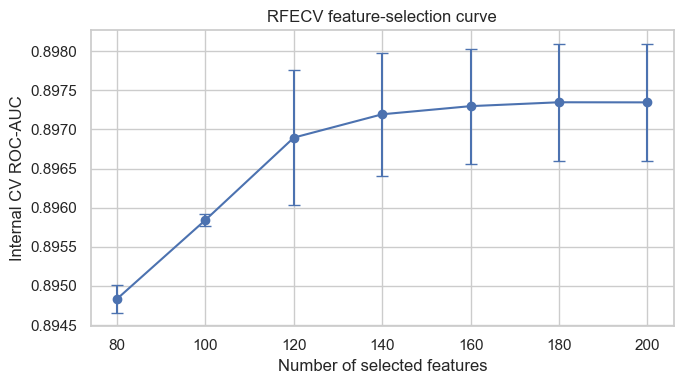

In [58]:
rfecv_curve = pd.DataFrame({
    "n_features": rfecv_fitted.named_steps["rfecv"].cv_results_["n_features"],
    "mean_roc_auc": rfecv_fitted.named_steps["rfecv"].cv_results_["mean_test_score"],
    "std_roc_auc": rfecv_fitted.named_steps["rfecv"].cv_results_["std_test_score"],
}).sort_values("n_features")

display(rfecv_curve)

plt.figure(figsize=(7, 4))
plt.errorbar(rfecv_curve["n_features"], rfecv_curve["mean_roc_auc"], yerr=rfecv_curve["std_roc_auc"], marker="o", capsize=4)
plt.xlabel("Number of selected features")
plt.ylabel("Internal CV ROC-AUC")
plt.title("RFECV feature-selection curve")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "rfecv_selection_curve.png", dpi=160, bbox_inches="tight")
plt.show()

RFECV evaluated subsets from 80 to 200 features after the preliminary SelectKBest step. On the full dataset, it selected 180 features. Across the two outer folds, the resulting feature space contained approximately 190 features on average.

For CatBoost, ROC-AUC increased from 0.8956 with 100 SelectKBest features to 0.9004 with RFECV, approaching the full-feature result of 0.9018. Thus, RFECV provides a compromise between the aggressive reduction of SelectKBest and the predictive performance of the full feature set.

# Experiment 5. Clinically motivated feature engineering

Hypothesis: summary measures of multimorbidity, functional limitations, and lifestyle risks, together with an age-by-comorbidity interaction, will improve prediction by making clinically meaningful cumulative burden explicit.

Meaning of the new features:
- comorbidity_count: number of confirmed chronic diagnoses;
- functional_limitations_count: number of confirmed functional limitations;
- lifestyle_risk_count: sum of six lifestyle risk factors;
- age_x_comorbidity: interaction between age and the number of diseases.

In [59]:
def add_engineered_features(data):
    engineered = data.copy()

    chronic_condition_columns = [
        "heart_attack", "heart_disease", "stroke", "asthma", "skin_cancer",
        "other_cancer", "copd", "depression", "kidney_disease", "diabetes",
        "arthritis",
    ]

    functional_limitation_columns = [
        "deaf", "blind", "cognitive_difficulty",
        "walking_difficulty", "dressing_difficulty", "errand_difficulty",
    ]

    engineered["comorbidity_count"] = (engineered[chronic_condition_columns] == 1).sum(axis=1)

    engineered["functional_limitations_count"] = (
        engineered[functional_limitation_columns] == 1
    ).sum(axis=1)

    engineered["lifestyle_risk_count"] = pd.DataFrame({
        "inactive": engineered["exercise"] == 2,
        "current_smoker": engineered["_smoking_status"].isin([1, 2]),
        "overweight_or_obese": engineered["_overweight"] == 2,
        "binge_drinking": engineered["_binge_drinking"] == 2,
        "low_fruit": engineered["_fruit_once"] == 2,
        "low_vegetables": engineered["_vegetable_once"] == 2,
    }, index=engineered.index).sum(axis=1)

    engineered["age_x_comorbidity"] = engineered["_age"] * engineered["comorbidity_count"]

    return engineered


X_engineered = add_engineered_features(X_model)

ENGINEERED_NUMERIC_FEATURES = [
    "comorbidity_count",
    "functional_limitations_count",
    "lifestyle_risk_count",
    "age_x_comorbidity",
]

display(X_engineered[ENGINEERED_NUMERIC_FEATURES].describe())

,comorbidity_count,functional_limitations_count,lifestyle_risk_count,age_x_comorbidity
count,437532.000000,437532.000000,437532.000000,437532.000000
mean,1.240595,0.502932,1.604705,76.657824
std,1.389899,0.969569,1.163388,94.930622
min,0.000000,0.000000,0.000000,0.000000
25%,0.000000,0.000000,1.000000,0.000000
50%,1.000000,0.000000,1.000000,52.000000
75%,2.000000,1.000000,2.000000,124.000000
max,11.000000,6.000000,6.000000,880.000000


In [60]:
engineered_transformer = Pipeline([
    ("preprocessing", build_preprocessor(X_engineered, ENGINEERED_NUMERIC_FEATURES)),
])

engineered_results = evaluate_models(X_engineered, y, engineered_transformer, make_models(balanced=False), "engineered")

display(summarize_results(engineered_results))
engineered_results.to_csv(RESULTS_DIR / "results_engineered.csv", index=False)

[18:28:26] engineered: experiment started

[18:28:26] engineered: fold 1/2 — preprocessing...
[18:28:29] Preprocessing completed in 3.3 sec
[18:28:29] logistic_regression: training...
[18:30:01] logistic_regression: training completed in 1.5 min; testing...
[18:30:01] logistic_regression: testing completed in 0.2 sec
[18:30:01] decision_tree: training...
[18:30:38] decision_tree: training completed in 0.6 min; testing...
[18:30:38] decision_tree: testing completed in 0.3 sec
[18:30:38] random_forest: training...
[18:33:35] random_forest: training completed in 3.0 min; testing...
[18:33:40] random_forest: testing completed in 4.5 sec
[18:33:40] linear_svc: training...
[18:34:33] linear_svc: training completed in 0.9 min; testing...
[18:34:33] linear_svc: testing completed in 0.1 sec
[18:34:33] catboost: training...
[18:34:44] catboost: training completed in 0.2 min; testing...
[18:34:45] catboost: testing completed in 0.8 sec
[18:34:46] engineered: fold 1/2 completed in 6.3 min

[18:34:

roc_auc              pr_auc            \
                                    mean       std      mean       std   
experiment model                                                         
engineered catboost             0.901859  0.000745  0.698773  0.001000   
           logistic_regression  0.898409  0.000966  0.690130  0.000022   
           linear_svc           0.898161  0.000940  0.691639  0.000265   
           random_forest        0.896763  0.000271  0.686199  0.000093   
           decision_tree        0.854539  0.000653  0.606527  0.000649   

                                      f1           precision            \
                                    mean       std      mean       std   
experiment model                                                         
engineered catboost             0.611014  0.001640  0.731975  0.001222   
           logistic_regression  0.603143  0.000255  0.734431  0.001868   
           linear_svc           0.592603  0.000254  0.743967  0.001178   
           random_forest        0.574176  0.000270  0.755803  0.001121   
           decision_tree        0.554285  0.000893  0.659182  0.005288   

                                  recall           balanced_accuracy  \
                                    mean       std              mean   
experiment model                                                       
engineered catboost             0.524367  0.003042          0.743040   
           logistic_regression  0.511678  0.001273          0.737392   
           linear_svc           0.492418  0.000165          0.729313   
           random_forest        0.462930  0.000069          0.716552   
           decision_tree        0.478217  0.004112          0.714452   

                                         fit_time_seconds             \
                                     std             mean        std   
experiment model                                                       
engineered catboost             0.001290        11.204003   0.117374   
           logistic_regression  0.000414        64.803857  38.368986   
           linear_svc           0.000028        64.192690  15.826575   
           random_forest        0.000059       180.088015   3.674933   
           decision_tree        0.001263        36.075431   0.176594   

                               output_features            
                                          mean       std  
experiment model                                          
engineered catboost                      881.5  21.92031  
           logistic_regression           881.5  21.92031  
           linear_svc                    881.5  21.92031  
           random_forest                 881.5  21.92031  
           decision_tree                 881.5  21.92031

There is no substantial improvement, because the new features are built from variables already present in the model:
- CatBoost can find interactions between age and diseases on its own;
- trees can form rules over several diagnoses on their own;
- the counts of diseases and limitations are a compact but redundant summary of the original features.

# Compare the feature experiments

In [61]:
all_feature_results = pd.concat([
    pd.read_csv(RESULTS_DIR / "results_full.csv"),
    pd.read_csv(RESULTS_DIR / "results_select_k_best.csv"),
    pd.read_csv(RESULTS_DIR / "results_svd.csv"),
    pd.read_csv(RESULTS_DIR / "results_rfecv.csv"),
    pd.read_csv(RESULTS_DIR / "results_engineered.csv"),
], ignore_index=True)

feature_comparison = all_feature_results.pivot_table(
    index="model",
    columns="experiment",
    values=[
        "roc_auc",
        "pr_auc",
        "f1",
        "precision",
        "recall",
        "balanced_accuracy",
        "fit_time_seconds",
        "output_features",
    ],
    aggfunc="mean",
)

display(feature_comparison)
feature_comparison.to_csv(RESULTS_DIR / "feature_experiment_comparison.csv")

balanced_accuracy                                    \
experiment                 engineered      full     rfecv select_k_best   
model                                                                     
catboost                     0.743040  0.743094  0.741880      0.735597   
decision_tree                0.714452  0.713133  0.719191      0.717624   
linear_svc                   0.729313  0.729187  0.726912      0.718379   
logistic_regression          0.737392  0.737251  0.734599      0.726896   
random_forest                0.716552  0.714999  0.725565      0.725903   

                                      f1                                    \
experiment                svd engineered      full     rfecv select_k_best   
model                                                                        
catboost             0.730221   0.611014  0.610951  0.608554      0.599748   
decision_tree        0.683494   0.554285  0.553636  0.563731      0.562768   
linear_svc           0.722523   0.592603  0.592435  0.589326      0.576000   
logistic_regression  0.729470   0.603143  0.602999  0.598980      0.587049   
random_forest        0.683275   0.574176  0.572187  0.586440      0.585637   

                              fit_time_seconds                          \
experiment                svd       engineered        full       rfecv   
model                                                                    
catboost             0.591170        11.204003   10.737366    6.143691   
decision_tree        0.492075        36.075431   31.265252   14.968076   
linear_svc           0.582060        64.192690   69.751122    6.198171   
logistic_regression  0.590862        64.803857   63.691544   17.482392   
random_forest        0.517205       180.088015  177.214285  164.997864   

                                              output_features                \
experiment          select_k_best         svd      engineered   full  rfecv   
model                                                                         
catboost                 5.003550    8.584761           881.5  877.5  190.0   
decision_tree            8.374352   30.286974           881.5  877.5  190.0   
linear_svc               2.960049    4.246865           881.5  877.5  190.0   
logistic_regression      9.231042    1.871993           881.5  877.5  190.0   
random_forest          128.996799  177.250059           881.5  877.5  190.0   

                                             pr_auc                      \
experiment          select_k_best    svd engineered      full     rfecv   
model                                                                     
catboost                    100.0  100.0   0.698773  0.698460  0.695333   
decision_tree               100.0  100.0   0.606527  0.609515  0.619821   
linear_svc                  100.0  100.0   0.691639  0.691583  0.690111   
logistic_regression         100.0  100.0   0.690130  0.690095  0.688067   
random_forest               100.0  100.0   0.686199  0.686779  0.685544   

                                             precision                      \
experiment          select_k_best       svd engineered      full     rfecv   
model                                                                        
catboost                 0.688002  0.681425   0.731975  0.731282  0.728263   
decision_tree            0.623172  0.507213   0.659182  0.666463  0.671512   
linear_svc               0.680905  0.685219   0.743967  0.744128  0.746671   
logistic_regression      0.679282  0.683773   0.734431  0.734767  0.734642   
random_forest            0.678756  0.659177   0.755803  0.759549  0.742256   

                                                recall                      \
experiment          select_k_best       svd engineered      full     rfecv   
model                                                                        
catboost                 0.730822  0.728496   0.524367  0.524628  0.522649   
decision_tree            0.678

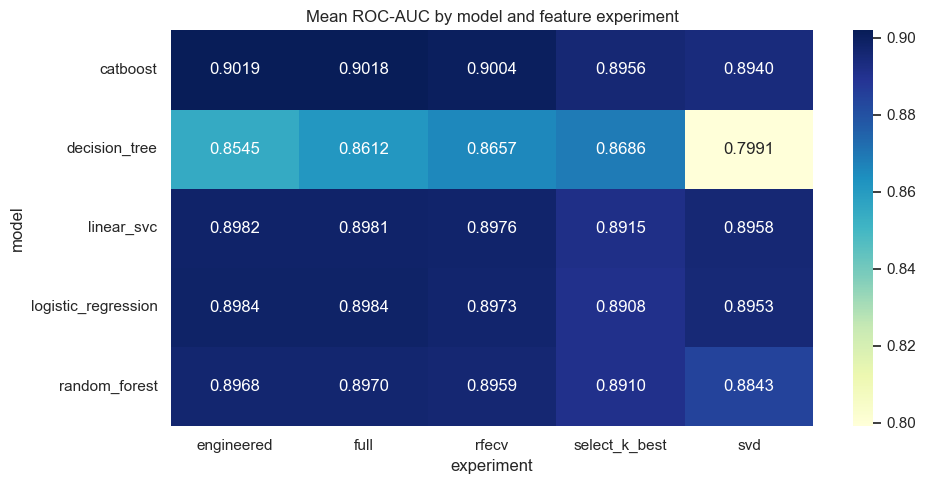

In [62]:
roc_auc_comparison = all_feature_results.pivot_table(
    index="model", columns="experiment", values="roc_auc", aggfunc="mean"
)
plt.figure(figsize=(10, 5))
sns.heatmap(roc_auc_comparison, annot=True, fmt=".4f", cmap="YlGnBu")
plt.title("Mean ROC-AUC by model and feature experiment")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_experiment_roc_auc.png", dpi=160, bbox_inches="tight")
plt.show()

CatBoost remains the strongest model for the full, engineered, RFECV, and SelectKBest representations. The engineered variant has the highest mean ROC-AUC, but its difference from the full representation is only 0.000056 and cannot be interpreted as a meaningful improvement.

RFECV provides the best feature-selection compromise: it reaches ROC-AUC 0.9004 for CatBoost while reducing the feature space from approximately 878 to 180 features. SelectKBest is faster and more compact but reduces CatBoost ROC-AUC to 0.8956. TruncatedSVD with 100 components is particularly suitable for the linear models, but it does not improve upon the full feature set.

experiment,engineered,full,rfecv,select_k_best,svd
model,,,,,
catboost,11.204003,10.737366,6.143691,5.003550,8.584761
decision_tree,36.075431,31.265252,14.968076,8.374352,30.286974
linear_svc,64.192690,69.751122,6.198171,2.960049,4.246865
logistic_regression,64.803857,63.691544,17.482392,9.231042,1.871993
random_forest,180.088015,177.214285,164.997864,128.996799,177.250059


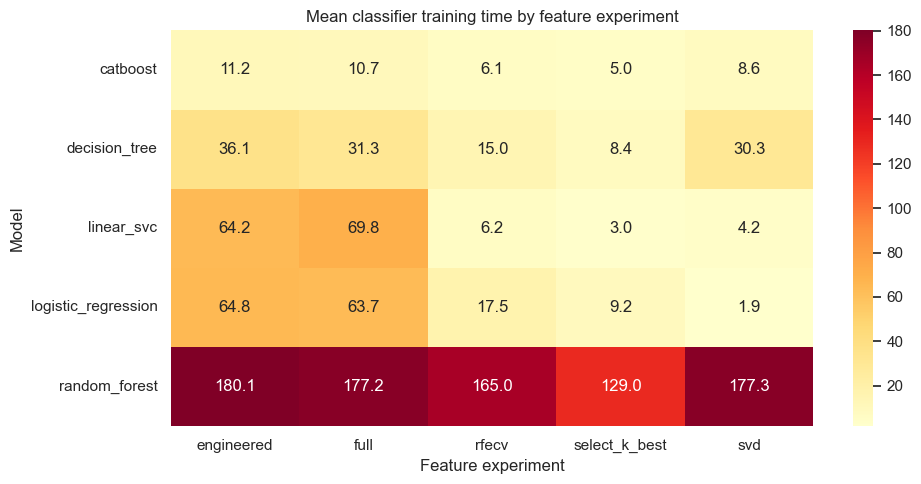

In [63]:
fit_time_comparison = all_feature_results.pivot_table(
    index="model",
    columns="experiment",
    values="fit_time_seconds",
    aggfunc="mean",
)

display(fit_time_comparison)

plt.figure(figsize=(10, 5))
sns.heatmap(
    fit_time_comparison,
    annot=True,
    fmt=".1f",
    cmap="YlOrRd",
)
plt.title("Mean classifier training time by feature experiment")
plt.xlabel("Feature experiment")
plt.ylabel("Model")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "feature_experiment_fit_time.png", dpi=160, bbox_inches="tight")
plt.show()

In [64]:
experiment_runtime = (
    all_feature_results
    .groupby("experiment")["experiment_time_seconds"]
    .first()
    .div(60)
    .rename("total_time_minutes")
    .to_frame()
)

display(experiment_runtime)

,total_time_minutes
experiment,
engineered,12.209668
full,12.081424
rfecv,10.587461
select_k_best,5.421467
svd,8.041976


# Class-imbalance experiment

All 5 models are compared with and without class weighting along with `BEST_FEATURE_VARIANT`

In [65]:
FEATURE_DATA = {
    "full": X_model,
    "select_k_best": X_model,
    "svd": X_model,
    "rfecv": X_model,
    "engineered": X_engineered,
}

FEATURE_TRANSFORMERS = {
    "full": full_transformer,
    "select_k_best": select_k_transformer,
    "svd": svd_transformer,
    "rfecv": rfecv_transformer,
    "engineered": engineered_transformer,
}

BEST_FEATURE_VARIANT = "engineered"

In [66]:
X_best = FEATURE_DATA[BEST_FEATURE_VARIANT]
best_feature_transformer = FEATURE_TRANSFORMERS[BEST_FEATURE_VARIANT]

balanced_results = evaluate_models(X_best, y, best_feature_transformer, make_models(balanced=True), f"{BEST_FEATURE_VARIANT}_balanced")

display(summarize_results(balanced_results))
balanced_results.to_csv(RESULTS_DIR / "results_balanced.csv", index=False)

[18:40:39] engineered_balanced: experiment started

[18:40:39] engineered_balanced: fold 1/2 — preprocessing...
[18:40:42] Preprocessing completed in 3.4 sec
[18:40:42] logistic_regression: training...
[18:42:37] logistic_regression: training completed in 1.9 min; testing...
[18:42:37] logistic_regression: testing completed in 0.2 sec
[18:42:37] decision_tree: training...
[18:43:23] decision_tree: training completed in 0.8 min; testing...
[18:43:23] decision_tree: testing completed in 0.3 sec
[18:43:23] random_forest: training...
[18:46:26] random_forest: training completed in 3.0 min; testing...
[18:46:30] random_forest: testing completed in 4.4 sec
[18:46:31] linear_svc: training...
[18:47:55] linear_svc: training completed in 1.4 min; testing...
[18:47:55] linear_svc: testing completed in 0.1 sec
[18:47:55] catboost: training...
[18:48:07] catboost: training completed in 0.2 min; testing...
[18:48:08] catboost: testing completed in 0.8 sec
[18:48:08] engineered_balanced: fold 1/2 co

roc_auc              pr_auc  \
                                             mean       std      mean   
experiment          model                                               
engineered_balanced catboost             0.901952  0.000910  0.697643   
                    logistic_regression  0.898801  0.001088  0.687332   
                    linear_svc           0.898083  0.001245  0.685542   
                    random_forest        0.896498  0.000513  0.685021   
                    decision_tree        0.840014  0.000365  0.595811   

                                                         f1            \
                                              std      mean       std   
experiment          model                                               
engineered_balanced catboost             0.000516  0.611786  0.003231   
                    logistic_regression  0.000355  0.615171  0.002444   
                    linear_svc           0.000204  0.617839  0.002319   
                    random_forest        0.000125  0.633996  0.000122   
                    decision_tree        0.000697  0.552727  0.002780   

                                        precision              recall  \
                                             mean       std      mean   
experiment          model                                               
engineered_balanced catboost             0.494146  0.001814  0.802945   
                    logistic_regression  0.505970  0.001599  0.784482   
                    linear_svc           0.513456  0.001607  0.775491   
                    random_forest        0.589213  0.000444  0.686147   
                    decision_tree        0.436404  0.001358  0.753605   

                                                  balanced_accuracy            \
                                              std              mean       std   
experiment          model                                                       
engineered_balanced catboost             0.006342          0.819521  0.003116   
                    logistic_regression  0.004106          0.815873  0.002140   
                    linear_svc           0.003640          0.814480  0.001946   
                    random_forest        0.000317          0.795379  0.000048   
                    decision_tree        0.006284          0.779769  0.002867   

                                        fit_time_seconds            \
                                                    mean       std   
experiment          model                                            
engineered_balanced catboost                   11.713564  0.029029   
                    logistic_regression       111.156853  4.191528   
                    linear_svc                 88.948907  6.251428   
                    random_forest             183.561114  1.298510   
                    decision_tree              45.878713  0.395399   

                                        output_features            
                                                   mean       std  
experiment          model                                          
engineered_balanced catboost                      881.5  21.92031  
                    logistic_regression           881.5  21.92031  
                    linear_svc                    881.5  21.92031  
                    random_forest                 881.5  21.92031  
                    decision_tree                 881.5  21.92031

In [67]:
unbalanced_best_results = all_feature_results[
    all_feature_results["experiment"] == BEST_FEATURE_VARIANT
].copy()
imbalance_comparison = pd.concat([unbalanced_best_results, balanced_results], ignore_index=True)
imbalance_summary = imbalance_comparison.pivot_table(
    index="model", columns="experiment",
    values=[
        "roc_auc",
        "pr_auc",
        "f1",
        "precision",
        "recall",
        "balanced_accuracy",
        "fit_time_seconds",
    ],
    aggfunc="mean",
)

display(imbalance_summary)
imbalance_summary.to_csv(RESULTS_DIR / "imbalance_comparison.csv")

balanced_accuracy                             f1  \
experiment                 engineered engineered_balanced engineered   
model                                                                  
catboost                     0.743040            0.819521   0.611014   
decision_tree                0.714452            0.779769   0.554285   
linear_svc                   0.729313            0.814480   0.592603   
logistic_regression          0.737392            0.815873   0.603143   
random_forest                0.716552            0.795379   0.574176   

                                        fit_time_seconds                      \
experiment          engineered_balanced       engineered engineered_balanced   
model                                                                          
catboost                       0.611786        11.204003           11.713564   
decision_tree                  0.552727        36.075431           45.878713   
linear_svc                     0.617839        64.192690           88.948907   
logistic_regression            0.615171        64.803857          111.156853   
random_forest                  0.633996       180.088015          183.561114   

                        pr_auc                      precision  \
experiment          engineered engineered_balanced engineered   
model                                                           
catboost              0.698773            0.697643   0.731975   
decision_tree         0.606527            0.595811   0.659182   
linear_svc            0.691639            0.685542   0.743967   
logistic_regression   0.690130            0.687332   0.734431   
random_forest         0.686199            0.685021   0.755803   

                                            recall                      \
experiment          engineered_balanced engineered engineered_balanced   
model                                                                    
catboost                       0.494146   0.524367            0.802945   
decision_tree                  0.436404   0.478217            0.753605   
linear_svc                     0.513456   0.492418            0.775491   
logistic_regression            0.505970   0.511678            0.784482   
random_forest                  0.589213   0.462930            0.686147   

                       roc_auc                      
experiment          engineered engineered_balanced  
model                                               
catboost              0.901859            0.901952  
decision_tree         0.854539            0.840014  
linear_svc            0.898161            0.898083  
logistic_regression   0.898409            0.898801  
random_forest         0.896763            0.896498

# Nested GridSearchCV for two best models

In [68]:
BEST_MODEL_NAMES = ["catboost", "logistic_regression"]
USE_BALANCED_MODELS = True

PARAM_GRIDS = {
    "catboost": {
        "model__iterations": [300, 600],
        "model__depth": [5, 7],
        "model__learning_rate": [0.03, 0.1],
    },
    "logistic_regression": {
        "model__C": [0.1, 1.0, 10.0],
    },
}

inner_cv = StratifiedKFold(n_splits=2, shuffle=True, random_state=RANDOM_STATE + 1)
outer_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)
nested_cv_splits = list(outer_cv.split(X_best, y))

nested_rows = []
selected_models = make_models(balanced=USE_BALANCED_MODELS)
nested_experiment_started = perf_counter()

for model_name in BEST_MODEL_NAMES:
    pipeline = Pipeline([
        ("features", clone(best_feature_transformer)),
        ("model", clone(selected_models[model_name])),
    ])

    for fold, (train_index, validation_index) in enumerate(nested_cv_splits, start=1):
        print(f"[{datetime.now():%H:%M:%S}] Nested CV: {model_name}, fold {fold}/{len(nested_cv_splits)} started", flush=True)

        search = GridSearchCV(
            estimator=pipeline,
            param_grid=PARAM_GRIDS[model_name],
            scoring="roc_auc",
            cv=inner_cv,
            refit=True,
            n_jobs=1,
            return_train_score=False,
        )

        started = perf_counter()
        search.fit(X_best.iloc[train_index], y.iloc[train_index])
        fit_time = perf_counter() - started

        y_validation = y.iloc[validation_index]
        y_pred = search.best_estimator_.predict(X_best.iloc[validation_index])
        y_score = prediction_scores(search.best_estimator_, X_best.iloc[validation_index])
        tn, fp, fn, tp = confusion_matrix(y_validation, y_pred, labels=[0, 1]).ravel()

        nested_rows.append({
            "model": model_name,
            "fold": fold,
            "roc_auc": roc_auc_score(y_validation, y_score),
            "pr_auc": average_precision_score(y_validation, y_score),
            "f1": f1_score(y_validation, y_pred, zero_division=0),
            "precision": precision_score(y_validation, y_pred, zero_division=0),
            "recall": recall_score(y_validation, y_pred, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_validation, y_pred),
            "tn": tn,
            "fp": fp,
            "fn": fn,
            "tp": tp,
            "fit_time_seconds": fit_time,
            "best_inner_roc_auc": search.best_score_,
            "best_params": json.dumps(search.best_params_),
        })

        print(f"[{datetime.now():%H:%M:%S}] Nested CV: {model_name}, fold {fold}/{len(nested_cv_splits)} completed in {fit_time / 60:.1f} min", flush=True)

nested_results = pd.DataFrame(nested_rows)
nested_experiment_time = perf_counter() - nested_experiment_started
nested_results["experiment_time_seconds"] = nested_experiment_time

display(nested_results.groupby("model")[["roc_auc", "pr_auc", "f1", "precision", "recall", "balanced_accuracy"]].agg(["mean", "std"]))
nested_results.to_csv(RESULTS_DIR / "nested_cv_results.csv", index=False)

print(f"[{datetime.now():%H:%M:%S}] Nested CV completed in {nested_experiment_time / 60:.1f} min")

[18:55:41] Nested CV: catboost, fold 1/3 started
[19:00:45] Nested CV: catboost, fold 1/3 completed in 5.0 min
[19:00:45] Nested CV: catboost, fold 2/3 started
[19:05:55] Nested CV: catboost, fold 2/3 completed in 5.1 min
[19:05:55] Nested CV: catboost, fold 3/3 started
[19:11:16] Nested CV: catboost, fold 3/3 completed in 5.3 min
[19:11:16] Nested CV: logistic_regression, fold 1/3 started
[19:19:40] Nested CV: logistic_regression, fold 1/3 completed in 8.4 min
[19:19:40] Nested CV: logistic_regression, fold 2/3 started
[19:25:38] Nested CV: logistic_regression, fold 2/3 completed in 5.9 min
[19:25:38] Nested CV: logistic_regression, fold 3/3 started
[19:32:50] Nested CV: logistic_regression, fold 3/3 completed in 7.2 min


roc_auc              pr_auc                  f1  \
                         mean       std      mean       std      mean   
model                                                                   
catboost             0.902302  0.001275  0.698603  0.002882  0.611834   
logistic_regression  0.899165  0.001165  0.688092  0.001384  0.615474   

                              precision              recall            \
                          std      mean       std      mean       std   
model                                                                   
catboost             0.002528  0.493393  0.001735  0.805103  0.004142   
logistic_regression  0.001681  0.506141  0.000972  0.785059  0.003205   

                    balanced_accuracy            
                                 mean       std  
model                                            
catboost                     0.820132  0.002218  
logistic_regression          0.816157  0.001575

[19:32:50] Nested CV completed in 37.1 min


Nested CV showed that CatBoost achieved the best ROC-AUC (0.9023), PR-AUC (0.6986), recall (0.8051), and balanced accuracy (0.8201). Logistic Regression produced slightly higher F1-score and precision. Class weighting substantially improved minority-class recall but reduced precision. Overall, CatBoost was selected as the best-performing model.

In [69]:
best_params_by_model = {}

for model_name in BEST_MODEL_NAMES:
    parameter_summary = (
        nested_results[nested_results["model"] == model_name]
        .groupby("best_params")
        .agg(
            selection_count=("fold", "count"),
            mean_inner_roc_auc=("best_inner_roc_auc", "mean"),
        )
        .sort_values(
            ["selection_count", "mean_inner_roc_auc"],
            ascending=[False, False],
        )
    )

    best_params_by_model[model_name] = json.loads(parameter_summary.index[0])

print(best_params_by_model)

{'catboost': {'model__depth': 7, 'model__iterations': 600, 'model__learning_rate': 0.03}, 'logistic_regression': {'model__C': 0.1}}


Automated hyperparameter optimization produced only a marginal improvement in predictive performance. However, the selected parameters differed from the initial settings: CatBoost changed from `depth=6`, `iterations=300`, and `learning_rate=0.1` to `depth=7`, `iterations=600`, and `learning_rate=0.03`, while Logistic Regression changed from `C=1.0` to `C=0.1`. This indicates that Logistic Regression benefited from stronger regularization, while CatBoost benefited from slower and more extensive boosting with a lower learning rate and more iterations.

In [70]:
tuned_pipelines = {}

for model_name in BEST_MODEL_NAMES:
    tuned_pipeline = Pipeline([
        ("features", clone(best_feature_transformer)),
        ("model", clone(selected_models[model_name])),
    ])

    tuned_pipelines[model_name] = tuned_pipeline.set_params(**best_params_by_model[model_name])

for model_name, pipeline in tuned_pipelines.items():
    print(f"\n{model_name}:")
    print(pipeline.named_steps["model"].get_params())


catboost:
{'iterations': 600, 'learning_rate': 0.03, 'depth': 7, 'loss_function': 'Logloss', 'thread_count': 4, 'random_seed': 42, 'verbose': False, 'auto_class_weights': 'Balanced', 'eval_metric': 'AUC', 'allow_writing_files': False}

logistic_regression:
{'C': 0.1, 'class_weight': 'balanced', 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': 1, 'penalty': 'l2', 'random_state': 42, 'solver': 'saga', 'tol': 0.001, 'verbose': 0, 'warm_start': False}


# Statistical comparison with Wilcoxon signed-rank test

The paired observations are the two models' ROC-AUC values on exactly the same ten outer folds.

In [71]:
comparison_cv = StratifiedKFold(n_splits=10, shuffle=True, random_state=RANDOM_STATE)
comparison_cv_splits = list(comparison_cv.split(X_best, y))

comparison_rows = []
comparison_prediction_rows = []
comparison_started = perf_counter()

for model_name, model_template in tuned_pipelines.items():
    for fold, (train_index, validation_index) in enumerate(comparison_cv_splits, start=1):
        print(f"[{datetime.now():%H:%M:%S}] Statistical CV: {model_name}, fold {fold}/10 started", flush=True)

        model = clone(model_template)

        started = perf_counter()
        model.fit(X_best.iloc[train_index], y.iloc[train_index])
        fit_time = perf_counter() - started

        y_validation = y.iloc[validation_index]
        y_pred = model.predict(X_best.iloc[validation_index])
        y_score = prediction_scores(model, X_best.iloc[validation_index])
        tn, fp, fn, tp = confusion_matrix(y_validation, y_pred, labels=[0, 1]).ravel()

        comparison_rows.append({
            "model": model_name,
            "fold": fold,
            "roc_auc": roc_auc_score(y_validation, y_score),
            "pr_auc": average_precision_score(y_validation, y_score),
            "f1": f1_score(y_validation, y_pred, zero_division=0),
            "precision": precision_score(y_validation, y_pred, zero_division=0),
            "recall": recall_score(y_validation, y_pred, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_validation, y_pred),
            "tn": tn,
            "fp": fp,
            "fn": fn,
            "tp": tp,
            "fit_time_seconds": fit_time,
        })

        comparison_prediction_rows.append(pd.DataFrame({
            "model": model_name,
            "fold": fold,
            "row_index": X_best.iloc[validation_index].index,
            "y_true": y_validation.to_numpy(),
            "y_pred": y_pred,
            "y_score": y_score,
        }))

        print(f"[{datetime.now():%H:%M:%S}] Statistical CV: {model_name}, fold {fold}/10 completed in {fit_time / 60:.1f} min", flush=True)

comparison_results = pd.DataFrame(comparison_rows)
comparison_predictions = pd.concat(comparison_prediction_rows, ignore_index=True)
comparison_time = perf_counter() - comparison_started

display(comparison_results.groupby("model")[["roc_auc", "pr_auc", "f1", "precision", "recall", "balanced_accuracy"]].agg(["mean", "std"]))

comparison_results.to_csv(RESULTS_DIR / "statistical_comparison_results.csv", index=False)
comparison_predictions.to_csv(RESULTS_DIR / "statistical_comparison_predictions.csv", index=False)

print(f"[{datetime.now():%H:%M:%S}] Statistical comparison completed in {comparison_time / 60:.1f} min")

[19:32:50] Statistical CV: catboost, fold 1/10 started


[19:33:40] Statistical CV: catboost, fold 1/10 completed in 0.8 min
[19:33:40] Statistical CV: catboost, fold 2/10 started
[19:34:33] Statistical CV: catboost, fold 2/10 completed in 0.9 min
[19:34:33] Statistical CV: catboost, fold 3/10 started
[19:35:27] Statistical CV: catboost, fold 3/10 completed in 0.9 min
[19:35:27] Statistical CV: catboost, fold 4/10 started
[19:36:23] Statistical CV: catboost, fold 4/10 completed in 0.9 min
[19:36:23] Statistical CV: catboost, fold 5/10 started
[19:37:17] Statistical CV: catboost, fold 5/10 completed in 0.9 min
[19:37:17] Statistical CV: catboost, fold 6/10 started
[19:38:13] Statistical CV: catboost, fold 6/10 completed in 0.9 min
[19:38:13] Statistical CV: catboost, fold 7/10 started
[19:39:08] Statistical CV: catboost, fold 7/10 completed in 0.9 min
[19:39:08] Statistical CV: catboost, fold 8/10 started
[19:40:02] Statistical CV: catboost, fold 8/10 completed in 0.9 min
[19:40:02] Statistical CV: catboost, fold 9/10 started
[19:40:57] Stati

roc_auc              pr_auc                  f1  \
                         mean       std      mean       std      mean   
model                                                                   
catboost             0.902491  0.001891  0.698923  0.004972  0.611252   
logistic_regression  0.899263  0.002030  0.688399  0.004244  0.615296   

                              precision              recall            \
                          std      mean       std      mean       std   
model                                                                   
catboost             0.003213  0.492073  0.002934  0.806643  0.006095   
logistic_regression  0.003261  0.505970  0.003553  0.784922  0.005130   

                    balanced_accuracy            
                                 mean       std  
model                                            
catboost                     0.820303  0.002834  
logistic_regression          0.816043  0.002469

[19:58:14] Statistical comparison completed in 25.4 min


model,catboost,logistic_regression,difference
fold,,,
1,0.902320,0.899202,0.003119
2,0.904044,0.900772,0.003272
3,0.903615,0.900551,0.003064
4,0.902000,0.898613,0.003387
5,0.903915,0.900893,0.003022
6,0.899085,0.895653,0.003432
7,0.900657,0.897472,0.003185
8,0.900671,0.897060,0.003611
9,0.905135,0.902051,0.003085


,model_a,model_b,mean_difference,median_difference,wilcoxon_w,p_value
0,catboost,logistic_regression,0.003228,0.003152,0.0,0.001953


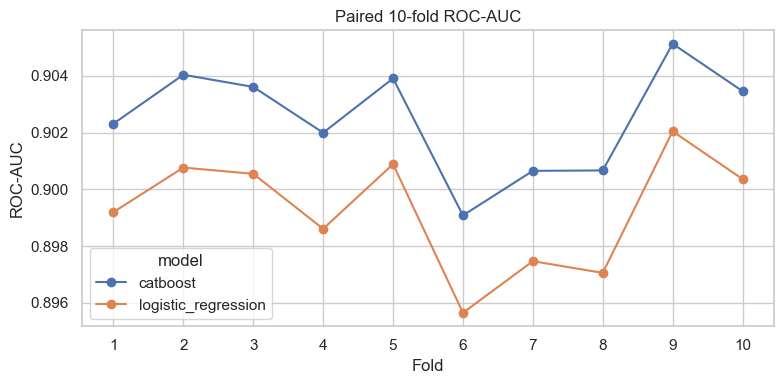

In [72]:
comparison_auc = comparison_results.pivot(index="fold", columns="model", values="roc_auc").sort_index()

model_order = comparison_auc.mean().sort_values(ascending=False).index.tolist()
model_a, model_b = model_order[:2]

auc_difference = comparison_auc[model_a] - comparison_auc[model_b]
wilcoxon_w, wilcoxon_p = wilcoxon(comparison_auc[model_a], comparison_auc[model_b], alternative="two-sided", method="auto")

paired_auc_results = comparison_auc[[model_a, model_b]].copy()
paired_auc_results["difference"] = auc_difference

display(paired_auc_results)
paired_auc_results.to_csv(RESULTS_DIR / "wilcoxon_paired_auc.csv")

wilcoxon_results = pd.DataFrame([{
    "model_a": model_a,
    "model_b": model_b,
    "mean_difference": auc_difference.mean(),
    "median_difference": auc_difference.median(),
    "wilcoxon_w": wilcoxon_w,
    "p_value": wilcoxon_p,
}])

display(wilcoxon_results)
wilcoxon_results.to_csv(RESULTS_DIR / "wilcoxon_test.csv", index=False)

ax = comparison_auc[[model_a, model_b]].plot(marker="o", figsize=(8, 4))
ax.set_xticks(comparison_auc.index)
ax.set_xlabel("Fold")
ax.set_ylabel("ROC-AUC")
ax.set_title("Paired 10-fold ROC-AUC")
plt.tight_layout()
plt.savefig(RESULTS_DIR / "wilcoxon_paired_scores.png", dpi=160, bbox_inches="tight")
plt.show()

CatBoost achieved a higher ROC-AUC than Logistic Regression in all ten folds, with a mean difference of 0.00323 and a median difference of 0.00315. The Wilcoxon signed-rank test produced W = 0 and p = 0.00195, indicating that the difference is statistically significant at the 0.05 level.

# Error analysis

The stratified 10-fold cross-validation produces one out-of-fold prediction for each respondent. We examine the three highest-confidence misclassifications made by the best model.

In [73]:
best_model_predictions = comparison_predictions[comparison_predictions["model"] == model_a].copy()
best_model_errors = best_model_predictions[best_model_predictions["y_true"] != best_model_predictions["y_pred"]].copy()

best_model_errors["wrong_class_probability"] = np.where(
    best_model_errors["y_pred"] == 1,
    best_model_errors["y_score"],
    1 - best_model_errors["y_score"],
)

top_errors = best_model_errors.sort_values("wrong_class_probability", ascending=False).head(3)
top_error_indices = top_errors["row_index"].tolist()

display(top_errors)

,model,fold,row_index,y_true,y_pred,y_score,wrong_class_probability
421870,catboost,10,281993,0,1,0.995262,0.995262
78328,catboost,2,345486,0,1,0.993601,0.993601
244496,catboost,6,256508,0,1,0.993118,0.993118


In [74]:
ERROR_ANALYSIS_FEATURES = [
    "_age",
    "_bmi",
    "physical_days",
    "mental_days",
    "limited_days",
    "sex",
    "exercise",
    "_smoking_status",
    "_income_group",
    "education",
    "heart_attack",
    "heart_disease",
    "stroke",
    "copd",
    "kidney_disease",
    "diabetes",
    "walking_difficulty",
    "depression",
    "comorbidity_count",
    "functional_limitations_count",
    "lifestyle_risk_count",
]

ERROR_ANALYSIS_FEATURES = [column for column in ERROR_ANALYSIS_FEATURES if column in X_best.columns]

error_examples = X_best.loc[top_error_indices, ERROR_ANALYSIS_FEATURES].copy()
top_errors_indexed = top_errors.set_index("row_index")

error_examples.insert(0, "true_class", top_errors_indexed.loc[top_error_indices, "y_true"].to_numpy())
error_examples.insert(1, "predicted_class", top_errors_indexed.loc[top_error_indices, "y_pred"].to_numpy())
error_examples.insert(2, "predicted_probability", top_errors_indexed.loc[top_error_indices, "y_score"].to_numpy())
error_examples.insert(3, "wrong_class_probability", top_errors_indexed.loc[top_error_indices, "wrong_class_probability"].to_numpy())

if "_bmi" in error_examples.columns:
    error_examples["_bmi"] = error_examples["_bmi"] / 100

display(error_examples)
error_examples.to_csv(RESULTS_DIR / "three_high_confidence_errors.csv")

,true_class,predicted_class,predicted_probability,wrong_class_probability,_age,_bmi,physical_days,mental_days,limited_days,sex,exercise,_smoking_status,_income_group,education,heart_attack,heart_disease,stroke,copd,kidney_disease,diabetes,walking_difficulty,depression,comorbidity_count,functional_limitations_count,lifestyle_risk_count
281993,0,1,0.995262,0.995262,57,26.57,30.0,30.0,77.0,2,2.0,4,3,2.0,2.0,7.0,1.0,1.0,7.0,1.0,1.0,1.0,4,5,3
345486,0,1,0.993601,0.993601,66,22.81,30.0,88.0,15.0,1,2.0,1,2,2.0,2.0,1.0,2.0,1.0,1.0,1.0,1.0,2.0,7,2,3
256508,0,1,0.993118,0.993118,80,21.26,25.0,25.0,20.0,2,2.0,4,9,2.0,1.0,1.0,2.0,2.0,2.0,1.0,1.0,1.0,6,5,1


All three selected cases are false positives: the respondents described their health as good or better, while CatBoost predicted fair or poor health with very high probability.

- Respondent 281993 was 57 years old and reported 30 physically unhealthy days, 30 mentally unhealthy days, no physical activity, stroke, COPD, diabetes, depression, and five functional limitations. The model's prediction is understandable because this profile strongly resembles the positive class. The error may reflect the subjective nature of self-reported general health or inconsistent survey responses.

- Respondent 345486 was 66 years old and reported 30 physically unhealthy days, no physical activity, daily smoking, heart disease, COPD, kidney disease, diabetes, walking difficulty, and seven chronic conditions. Despite this high disease burden, the respondent classified their health as good or better.

- Respondent 256508 was 80 years old and reported 25 physically and mentally unhealthy days, no physical activity, cardiovascular disease, diabetes, depression, and five functional limitations. Again, the available predictors strongly support fair or poor health, while the self-reported target belongs to the opposite class.

These cases suggest that some errors are caused not only by model limitations but also by the subjective definition of the target and possible inconsistencies between the overall health rating and the detailed questionnaire answers.

# Explainability

SHAP provides global feature-importance estimates and local explanations for the selected high-confidence errors.

In [76]:
FINAL_MODEL_NAME = model_a
final_model = clone(tuned_pipelines[FINAL_MODEL_NAME])
final_model.fit(X_best, y)

print("Final model:", FINAL_MODEL_NAME)
print("Final parameters:", best_params_by_model[FINAL_MODEL_NAME])

Final model: catboost
Final parameters: {'model__depth': 7, 'model__iterations': 600, 'model__learning_rate': 0.03}


In [81]:
feature_transformer = final_model.named_steps["features"]
final_estimator = final_model.named_steps["model"]

shap_sample = X_best.sample(n=1000, random_state=RANDOM_STATE)
shap_transformed = feature_transformer.transform(shap_sample)

if issparse(shap_transformed):
    shap_transformed = shap_transformed.toarray()

shap_feature_names = feature_transformer.get_feature_names_out()
shap_background = shap_transformed[:200]

explainer = shap.Explainer(final_estimator, shap_background, feature_names=shap_feature_names)
shap_values = explainer(shap_transformed)

if shap_values.values.ndim == 3:
    shap_values = shap_values[:, :, 1]

 99%|===================| 988/1000 [00:28<00:00]        

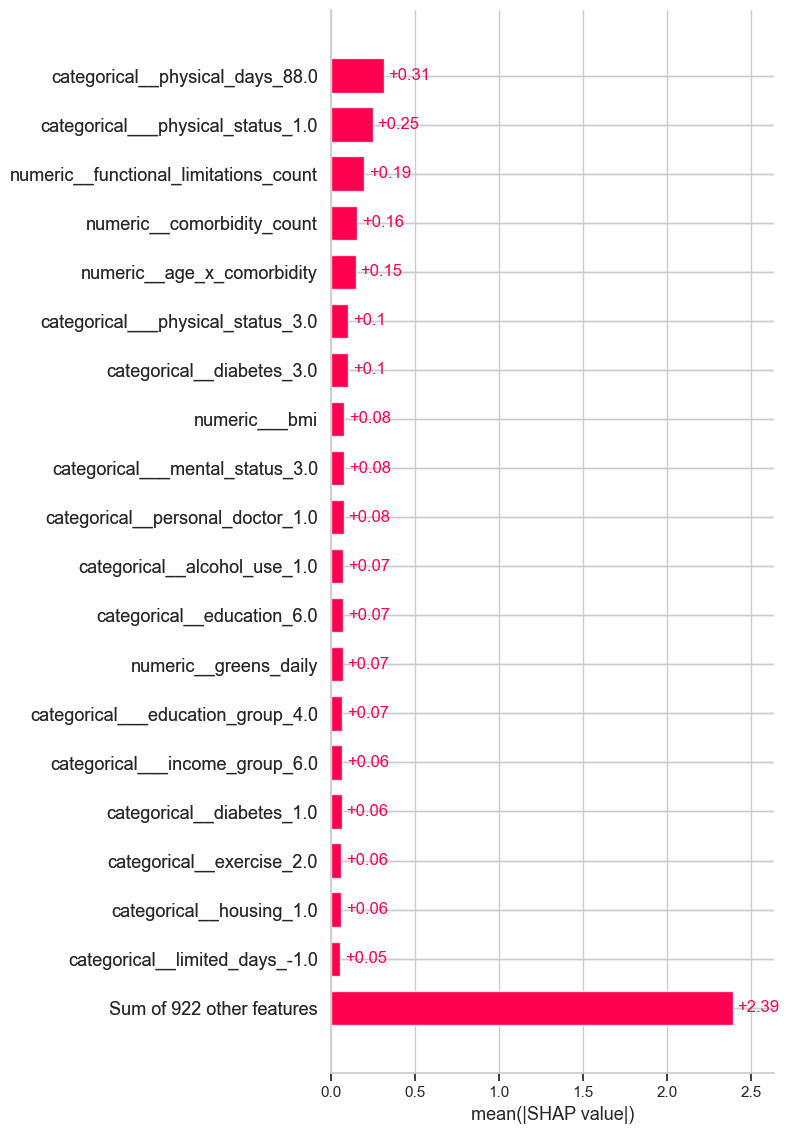

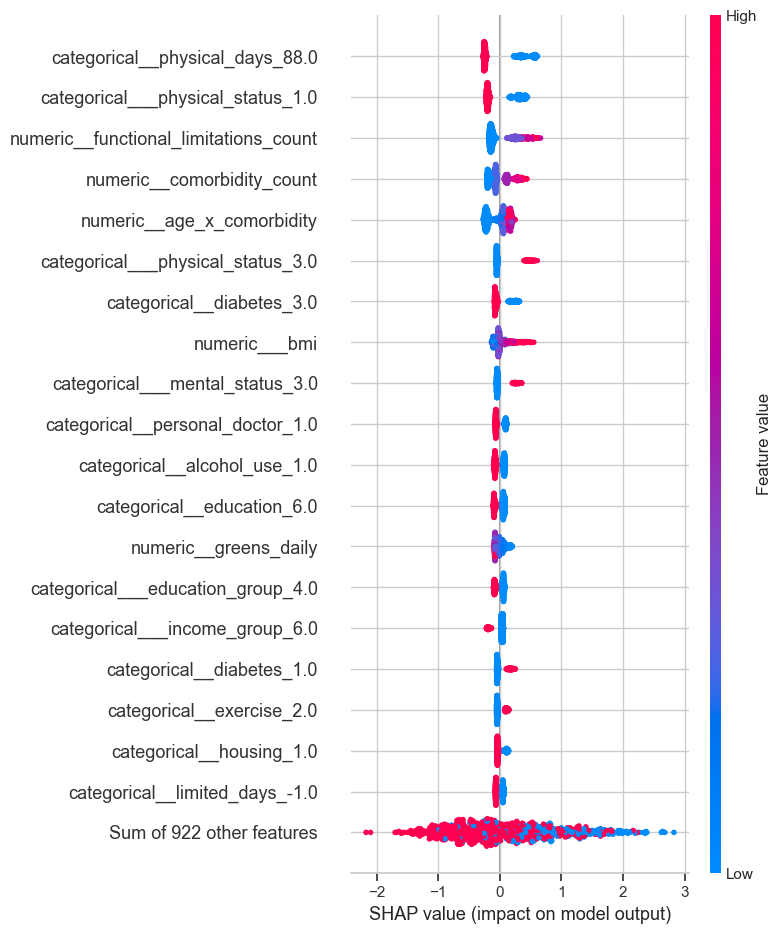

In [82]:
shap.plots.bar(shap_values, max_display=20, show=False)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "shap_global_bar.png", dpi=160, bbox_inches="tight")
plt.show()

shap.plots.beeswarm(shap_values, max_display=20, show=False)
plt.tight_layout()
plt.savefig(RESULTS_DIR / "shap_beeswarm.png", dpi=160, bbox_inches="tight")
plt.show()

The global SHAP importance plot shows that the model relies primarily on physical health, functional limitations, chronic disease burden, age-related comorbidity, BMI, diabetes, and physical activity. Several highly ranked variables, such as `physical_days` and `_physical_status`, describe related aspects of physical health, so their importance is distributed across multiple encoded features.

The SHAP beeswarm plot additionally shows the direction of these effects. Positive SHAP values move predictions toward **Fair or poor health**, while negative values move them toward **Good or better health**. 

Specifically, `physical_days_88.0` and `physical_status_1.0` both represent zero days when physical health was not good during the previous 30 days. When these indicators are active, they move predictions toward **Good or better health**. In contrast, `physical_status_3.0`, representing 14–30 physically unhealthy days, moves predictions toward **Fair or poor health**. In contrast, `physical_status_3.0`, which represents 14–30 days of poor physical health, shifts predictions toward Fair or poor health.

High values of `functional_limitations_count`, `comorbidity_count`, and `age_x_comorbidity` have mostly positive SHAP values, showing that multiple limitations and diseases—especially at an older age—increase the predicted risk. The indicators `diabetes_1.0` and `exercise_2.0`, representing diagnosed diabetes and no physical activity, also shift predictions toward **Fair or poor health**, while `diabetes_3.0`, representing no diabetes, shifts them toward **Good or better health**. Higher BMI generally increases the predicted risk, whereas the categories corresponding to higher education and income tend to reduce it.

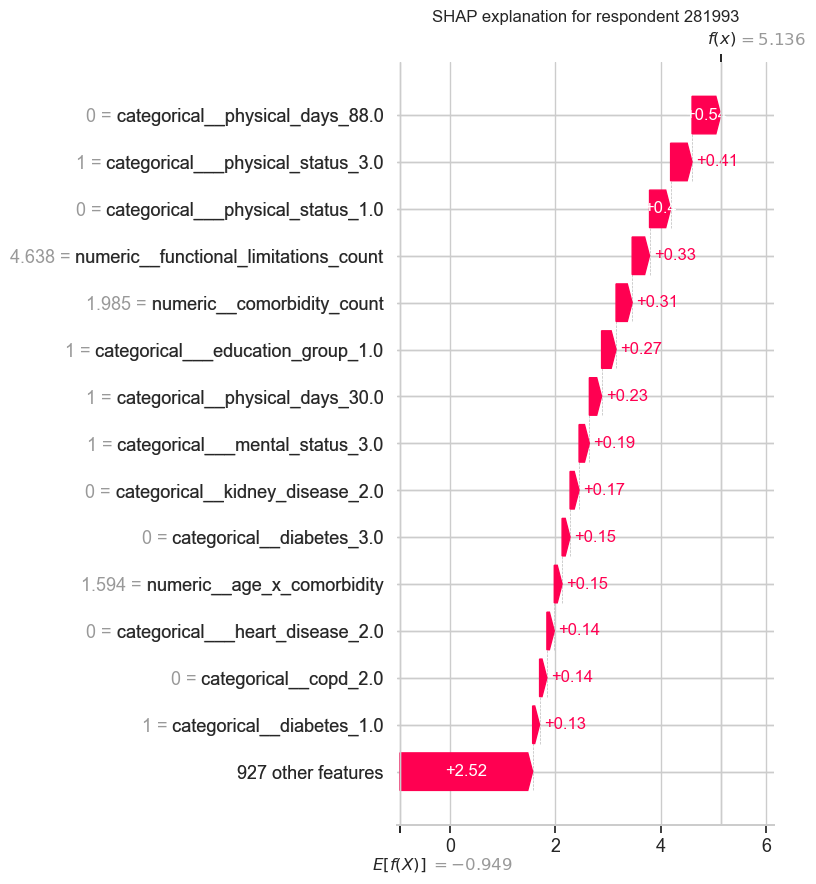

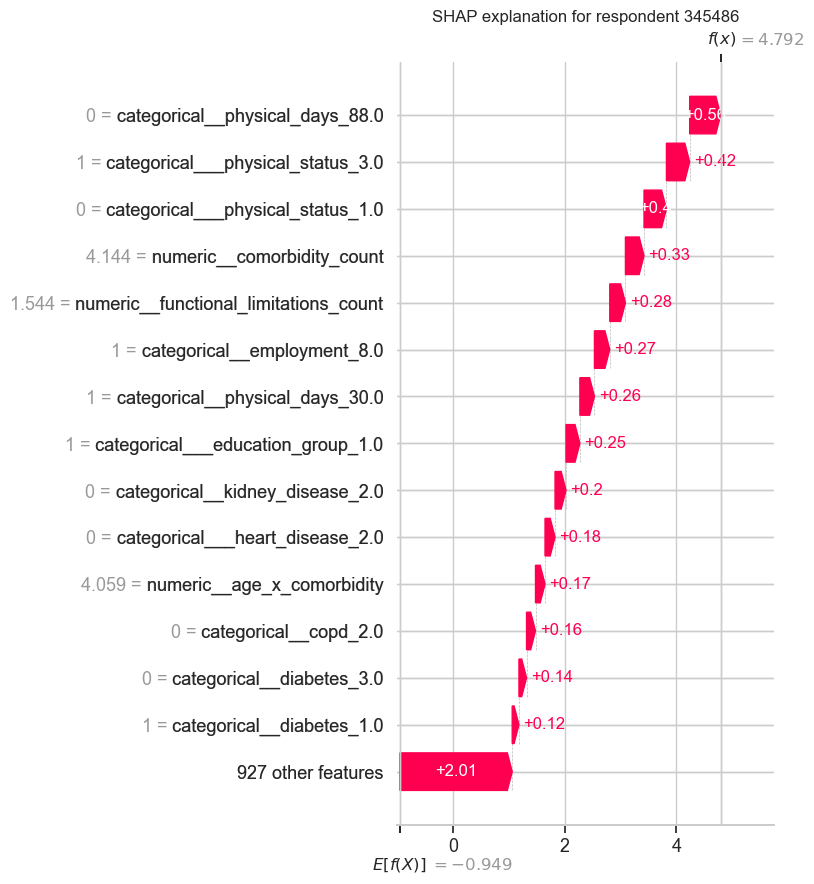

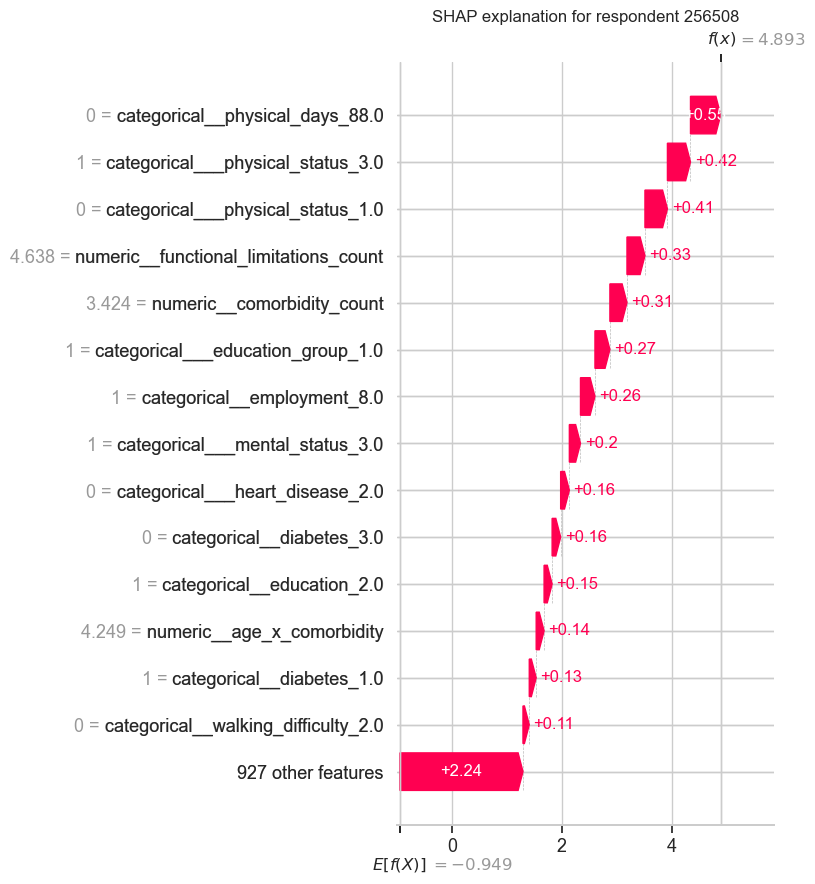

In [83]:
error_transformed = feature_transformer.transform(X_best.loc[top_error_indices])

if issparse(error_transformed):
    error_transformed = error_transformed.toarray()

error_shap_values = explainer(error_transformed)

if error_shap_values.values.ndim == 3:
    error_shap_values = error_shap_values[:, :, 1]

for position, row_index in enumerate(top_error_indices):
    shap.plots.waterfall(error_shap_values[position], max_display=15, show=False)
    plt.title(f"SHAP explanation for respondent {row_index}")
    plt.tight_layout()
    plt.savefig(RESULTS_DIR / f"shap_error_{row_index}.png", dpi=160, bbox_inches="tight")
    plt.show()

The local SHAP waterfall plots explain why CatBoost assigned a very high probability of Fair or poor health to each of the three misclassified respondents. The first two respondents reported 30 days of poor physical health during the previous month, while the third reported 25 days. Therefore, `physical_status_3.0`, representing 14–30 such days, is active for all three respondents, whereas `physical_days_88.0` and `physical_status_1.0`, both representing zero days of poor physical health, are inactive. This strongly shifted the model’s predictions toward **Fair or poor health**. Additional positive contributions came from high standardized values of comorbidity and functional limitation counts, diabetes, low education, and, for two respondents, being unable to work.